## Projet ML P1 IA G5 : Segmentation Client

Groupe 5 :

* __Rokhaya Coumba Diouf__
* __Yohan Fredy Hounyouvi__
* __Khadidiatou Gueye__
* __Cheikh Ahmed Tidiane Ciss__

### Segmentation de la clientèle d'un grossiste

#### 0. Introduction

##### 0.1 Contexte métier
Un grossiste portugais en produits alimentaires approvisionne différents types de clients professionnels (B2B) : hôtels, restaurants, cafés, épiceries, supérettes, etc.

Aujourd'hui, il applique la **même stratégie** (logistique, offre commerciale, marketing) à tous ses clients, alors que leurs besoins et leurs volumes d'achat sont très différents.

Toute décision globale, par exemple réduire la fréquence des livraisons pour baisser les coûts, risque donc de **satisfaire certains clients et d'en mécontenter d'autres**. Le grossiste a besoin de mieux connaître sa clientèle pour adapter ses décisions à chaque type de client.

### 0.2 Problématique
> Peut-on identifier des groupes de clients homogènes à partir de leurs habitudes de dépenses, et en tirer des recommandations concrètes pour le grossiste ?

### 0.3 Objectifs
1. Explorer et comprendre le comportement d'achat des clients.
2. Construire une segmentation par **apprentissage non supervisé** (clustering).
3. Déterminer un nombre de segments pertinent et justifié.
4. Interpréter chaque segment (persona) et valider la segmentation.
5. Proposer des recommandations métier adaptées à chaque segment.

### 0.4 Description du jeu de données
**Source :** *Wholesale Customers Data Set*, UCI Machine Learning Repository.
Chaque ligne correspond à un client. Les variables de dépenses sont des **montants annuels** (en unités monétaires).

| Variable | Type | Description |
|---|---|---|
| `Channel` | Catégorielle | Canal de vente : 1 = Horeca (Hôtels/Restaurants/Cafés), 2 = Retail (commerce de détail) |
| `Region` | Catégorielle | Région : 1 = Lisbonne, 2 = Porto, 3 = Autre |
| `Fresh` | Numérique | Dépenses annuelles en produits frais |
| `Milk` | Numérique | Dépenses annuelles en produits laitiers |
| `Grocery` | Numérique | Dépenses annuelles en épicerie |
| `Frozen` | Numérique | Dépenses annuelles en surgelés |
| `Detergents_Paper` | Numérique | Dépenses annuelles en détergents et produits papier |
| `Delicassen` | Numérique | Dépenses annuelles en produits traiteur / épicerie fine |

### 0.5 Démarche générale
Le dataset ne contient **aucune variable cible** : il s'agit donc d'un problème d'**apprentissage non supervisé**.

**Choix méthodologique :** la segmentation sera construite uniquement à partir des **6 variables de dépenses**. Les variables `Channel` et `Region` seront mises de côté pour servir à **l'interprétation et à la validation** des segments. Si nos clusters retrouvent la distinction Horeca/Retail sans l'avoir vue pendant l'apprentissage, cela confirmera que la segmentation capte une structure réelle des données.

**Étapes du projet :**
1. Imports et chargement des données
2. Analyse exploratoire (EDA)
3. Prétraitement
4. Réduction de dimension (ACP)
5. Modélisation (K-Means, CAH, GMM)
6. Interprétation des segments
7. Evaluation et Validation
8. Affectation d'un nouveau client
9. Recommandations métier et conclusion

### 1. Le Machine Learning non supervisé

#### 1.1 Supervisé vs non supervisé
En Machine Learning, on distingue deux grandes familles d'apprentissage :

| | Apprentissage supervisé | Apprentissage non supervisé |
|---|---|---|
| **Données** | Variables explicatives **+ une variable cible** (étiquette) | Variables explicatives **uniquement**, sans étiquette |
| **Objectif** | Apprendre à **prédire** la cible | **Découvrir des structures cachées** dans les données |
| **Exemples de tâches** | Classification, régression | Clustering, réduction de dimension, détection d'anomalies |
| **Évaluation** | Comparaison prédiction / vraie valeur (accuracy, RMSE…) | Pas de « bonne réponse » : métriques internes (silhouette…) et interprétation métier |

#### 1.2 Pourquoi le non supervisé dans notre cas ?
Dans notre dataset, **aucune colonne n'indique à quel segment appartient chaque client** : les segments n'existent pas encore, c'est justement ce qu'on cherche à découvrir.
On ne peut donc pas entraîner un modèle supervisé. On utilise le **clustering**, qui regroupe automatiquement les clients selon la similarité de leurs dépenses.

#### 1.3 Le clustering
Le clustering consiste à partitionner les observations en groupes (**clusters**) tels que :
- les clients d'un **même cluster** soient **le plus similaires possible** (forte homogénéité intra-cluster) ;
- les clients de **clusters différents** soient **le plus différents possible** (forte séparation inter-clusters).

La similarité est généralement mesurée par une **distance** (souvent la distance euclidienne) entre les profils de dépenses. Cela implique que les variables soient **à la même échelle**, d'où l'importance du prétraitement (standardisation).

Principaux algorithmes envisagés dans ce projet :
- **K-Means** : affecte chaque client au centre de cluster le plus proche, en minimisant la variance intra-cluster. Le nombre de clusters *k* doit être choisi à l'avance.
- **Clustering hiérarchique (CAH)** : construit un arbre de regroupements successifs (dendrogramme), utile pour visualiser et choisir le nombre de groupes.
- **Modèles de mélange gaussien (GMM)** : approche probabiliste où chaque client a une probabilité d'appartenance à chaque cluster.

#### 1.4 Application à la segmentation client
Appliqué à notre problème, le clustering permettra de passer de **440 clients traités de la même façon** à **quelques segments** au comportement d'achat homogène, chacun pouvant faire l'objet d'une stratégie commerciale et logistique adaptée.

### Étape 3 : Chargement du dataset avec Pandas

#### 2. Chargement des données

##### 2.1 Import des bibliothèques
**Pourquoi :** on importe les bibliothèques utilisées dans cette partie :
- **Pandas** : manipulation de données tabulaires (DataFrame) ;
- **NumPy** : calcul numérique ;
- **Matplotlib** et **Seaborn** : visualisation.

On fixe aussi une **graine aléatoire** (`RANDOM_STATE`) pour garantir la **reproductibilité** des résultats, car certaines étapes du projet (K-Means, GMM) dépendent d'une initialisation aléatoire.

In [5]:
%pip install numpy pandas matplotlib seaborn  
# --- Manipulation des données ---
import numpy as np
import pandas as pd

# --- Visualisation ---
import matplotlib.pyplot as plt
import seaborn as sns

# --- Divers ---
import warnings
warnings.filterwarnings("ignore")

# --- Paramètres globaux ---
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Style des graphiques
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 6)

# Affichage pandas : toutes les colonnes, 2 décimales
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.2f}".format)

print("Bibliothèques importées avec succès.")


[notice] A new release of pip is available: 23.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


  Obtaining dependency information for pandas from https://files.pythonhosted.org/packages/69/7c/8da507fc9ef7218aba9f6d66be872e3db09d3d4aa4b540ad27885ad89f02/pandas-3.1.1-cp311-cp311-win_amd64.whl.metadata
  Obtaining dependency information for seaborn from https://files.pythonhosted.org/packages/83/11/00d3c3dfc25ad54e731d91449895a79e4bf2384dc3ac01809010ba88f6d5/seaborn-0.13.2-py3-none-any.whl.metadata
  Obtaining dependency information for tzdata from https://files.pythonhosted.org/packages/0a/66/9a06c2227fedfd4919f0eaaa8b94377d9730882a7e4f95823c9a331ab5e1/tzdata-2026.6-py2.py3-none-any.whl.metadata
   ---------------------------------------- 0.0/11.0 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.0 MB 991.0 kB/s eta 0:00:12
    --------------------------------------- 0.2/11.0 MB 1.7 MB/s eta 0:00:07
   - -------------------------------------- 0.3/11.0 MB 1.8 MB/s eta 0:00:06
   - -------------------------------------- 0.5/11.0 MB 2.1 MB/s eta 0:00:06
   --- -----

### 2.2 Lecture du fichier CSV
**Pourquoi :** on charge le fichier dans un DataFrame Pandas, puis on affiche les premières lignes pour vérifier que la lecture s'est bien passée (bon séparateur, bons noms de colonnes, valeurs cohérentes).

In [6]:
# Chargement du dataset
df = pd.read_csv("data/Wholesale customers data.csv")

print("Dataset chargé avec succès.")
df.head()

Dataset chargé avec succès.


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [7]:
# Aperçu des dernières lignes et d'un échantillon aléatoire
display(df.tail())
display(df.sample(5, random_state=RANDOM_STATE))

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
435,1,3,29703,12051,16027,13135,182,2204
436,1,3,39228,1431,764,4510,93,2346
437,2,3,14531,15488,30243,437,14841,1867
438,1,3,10290,1981,2232,1038,168,2125
439,1,3,2787,1698,2510,65,477,52


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
265,1,1,5909,23527,13699,10155,830,3636
78,1,3,10766,1175,2067,2096,301,167
347,2,3,27380,7184,12311,2809,4621,1022
255,1,1,31614,489,1495,3242,111,615
327,1,2,542,899,1664,414,88,522


### 2.3 Définition des groupes de variables
**Pourquoi :** on sépare dès maintenant les variables en deux groupes, qu'on réutilisera dans tout le notebook :
- les **variables catégorielles** (`Channel`, `Region`), qui serviront à l'interprétation et à la validation ;
- les **variables de dépenses**, qui serviront à construire la segmentation.

On crée aussi des dictionnaires de correspondance pour remplacer les codes numériques par des libellés lisibles dans les graphiques.

In [8]:
# Groupes de variables
CAT_COLS = ["Channel", "Region"]
SPEND_COLS = ["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicassen"]

# Correspondance codes -> libellés
channel_map = {1: "Horeca", 2: "Retail"}
region_map = {1: "Lisbonne", 2: "Porto", 3: "Autre"}

print("Variables catégorielles :", CAT_COLS)
print("Variables de dépenses   :", SPEND_COLS)

Variables catégorielles : ['Channel', 'Region']
Variables de dépenses   : ['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']


**Observation :** le fichier est correctement chargé. Les 8 colonnes attendues sont présentes, avec des noms cohérents avec la description du dataset. Les variables de dépenses prennent des valeurs très variables d'un client à l'autre (de quelques unités à plusieurs dizaines de milliers), ce que nous analyserons en détail dans l'exploration.

#### Étape 4 : Exploration de la structure des données

##### 3.1 Dimensions du dataset
**Pourquoi :** connaître le nombre d'observations et de variables permet de juger de la taille du problème et du choix des méthodes. Avec peu de données, par exemple, il faut être prudent sur le nombre de clusters.

In [9]:
print(f"Nombre de lignes (clients)   : {df.shape[0]}")
print(f"Nombre de colonnes (variables) : {df.shape[1]}")

Nombre de lignes (clients)   : 440
Nombre de colonnes (variables) : 8


**Observation :** le dataset contient **440 clients** décrits par **8 variables**. C'est un jeu de données de petite taille : les algorithmes s'exécuteront rapidement, mais chaque valeur extrême aura un poids important sur les résultats.

### 3.2 Types de variables
**Pourquoi :** vérifier que chaque colonne a le type attendu (numérique ou catégoriel). Une variable mal typée peut fausser les calculs et les graphiques.

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB


In [11]:
# Tableau récapitulatif : type pandas et nature réelle de chaque variable
types_df = pd.DataFrame({
    "Type pandas": df.dtypes,
    "Nature": ["Catégorielle" if col in CAT_COLS else "Numérique continue" for col in df.columns]
})
types_df

,Type pandas,Nature
Channel,int64,Catégorielle
Region,int64,Catégorielle
Fresh,int64,Numérique continue
Milk,int64,Numérique continue
Grocery,int64,Numérique continue
Frozen,int64,Numérique continue
Detergents_Paper,int64,Numérique continue
Delicassen,int64,Numérique continue


**Observation :**
- Les 8 variables sont stockées en **entiers (`int64`)**.
- Attention : `Channel` et `Region` sont codées en chiffres, mais ce sont des **variables catégorielles** (nominales). Leurs valeurs n'ont pas de sens numérique : la région 3 n'est pas « plus grande » que la région 1. Elles ne doivent donc **pas être traitées comme des nombres** dans le clustering.
- Les 6 variables de dépenses sont des **variables quantitatives continues** (montants annuels).

#### 3.3 Description statistique
**Pourquoi :** les statistiques descriptives résument l'ordre de grandeur, la dispersion et l'étendue de chaque variable de dépenses. Comparer la **moyenne** et la **médiane** donne un premier indice d'asymétrie : si la moyenne est nettement supérieure à la médiane, quelques valeurs très élevées tirent la moyenne vers le haut.

In [12]:
# Statistiques descriptives des variables de dépenses
stats = df[SPEND_COLS].describe().T
stats["median"] = df[SPEND_COLS].median()
stats["mean/median"] = stats["mean"] / stats["median"]
stats["cv (std/mean)"] = stats["std"] / stats["mean"]   # coefficient de variation
stats

,count,mean,std,min,25%,50%,75%,max,median,mean/median,cv (std/mean)
Fresh,440.00,12000.30,12647.33,3.00,3127.75,8504.00,16933.75,112151.00,8504.00,1.41,1.05
Milk,440.00,5796.27,7380.38,55.00,1533.00,3627.00,7190.25,73498.00,3627.00,1.60,1.27
Grocery,440.00,7951.28,9503.16,3.00,2153.00,4755.50,10655.75,92780.00,4755.50,1.67,1.20
Frozen,440.00,3071.93,4854.67,25.00,742.25,1526.00,3554.25,60869.00,1526.00,2.01,1.58
Detergents_Paper,440.00,2881.49,4767.85,3.00,256.75,816.50,3922.00,40827.00,816.50,3.53,1.65
Delicassen,440.00,1524.87,2820.11,3.00,408.25,965.50,1820.25,47943.00,965.50,1.58,1.85


In [13]:
# Dépense totale par client et part moyenne de chaque catégorie
total = df[SPEND_COLS].sum(axis=1)
print("Dépense annuelle totale par client :")
print(total.describe().round(2), "\n")

part_moyenne = (df[SPEND_COLS].sum() / df[SPEND_COLS].sum().sum() * 100).sort_values(ascending=False)
print("Part de chaque catégorie dans les dépenses totales (%) :")
print(part_moyenne.round(1))

Dépense annuelle totale par client :
count      440.00
mean     33226.14
std      26356.30
min        904.00
25%      17448.75
50%      27492.00
75%      41307.50
max     199891.00
dtype: float64 

Part de chaque catégorie dans les dépenses totales (%) :
Fresh              36.10
Grocery            23.90
Milk               17.40
Frozen              9.20
Detergents_Paper    8.70
Delicassen          4.60
dtype: float64


**Observations :**
- **`Fresh`** est la catégorie qui pèse le plus en moyenne (≈ 12 000), suivie de `Grocery` (≈ 7 950) et `Milk` (≈ 5 800). `Delicassen` est la plus faible (≈ 1 525).
- Pour **toutes** les variables, la **moyenne est nettement supérieure à la médiane** (par exemple `Detergents_Paper` : moyenne ≈ 2 880 contre médiane ≈ 816). Les distributions sont donc **asymétriques à droite** : la majorité des clients dépense peu, et quelques clients dépensent énormément.
- L'**écart-type est très élevé**, souvent du même ordre que la moyenne ou plus (coefficient de variation proche de 1 ou supérieur) : les clients sont **très hétérogènes**, ce qui est plutôt encourageant pour une segmentation.
- L'**étendue est considérable** : des minimums à quelques unités (3 en `Fresh`, `Grocery`, `Detergents_Paper`) et des maximums très élevés (112 151 en `Fresh`, 92 780 en `Grocery`, 60 869 en `Frozen`). Cela signale la présence probable de **valeurs extrêmes**, à étudier.

- En volume total, `Fresh` représente **36 %** des dépenses de l'ensemble des clients, devant `Grocery` (24 %) et `Milk` (17 %). `Delicassen` ne représente que 4,6 %. La dépense annuelle totale médiane d'un client est d'environ **27 500**, avec un maximum de près de **200 000**.

Ces constats suggèrent qu'une **transformation des données** (par exemple logarithmique) sera nécessaire avant le clustering.

### 3.4 Valeurs manquantes et doublons
**Pourquoi :** les algorithmes de clustering ne gèrent pas les valeurs manquantes, et des doublons donneraient un poids artificiel à certains clients.

In [14]:
missing = pd.DataFrame({
    "Nb manquants": df.isnull().sum(),
    "% manquants": (df.isnull().mean() * 100).round(2)
})
display(missing)

print(f"Nombre de lignes dupliquées : {df.duplicated().sum()}")
print(f"Nombre de dépenses négatives : {(df[SPEND_COLS] < 0).sum().sum()}")

,Nb manquants,% manquants
Channel,0,0.00
Region,0,0.00
Fresh,0,0.00
Milk,0,0.00
Grocery,0,0.00
Frozen,0,0.00
Detergents_Paper,0,0.00
Delicassen,0,0.00


Nombre de lignes dupliquées : 0
Nombre de dépenses négatives : 0


**Observation :** le dataset ne contient **aucune valeur manquante**, **aucun doublon** et **aucune dépense négative**. Aucun traitement d'imputation ou de nettoyage n'est nécessaire à ce stade.

#### 3.5 Valeurs uniques
**Pourquoi :** le nombre de valeurs uniques confirme la nature des variables (peu de modalités = catégorielle, beaucoup = continue) et permet d'étudier la répartition des clients par canal et par région.

In [15]:
# Nombre de valeurs uniques par variable
df.nunique().to_frame("Nb valeurs uniques")

,Nb valeurs uniques
Channel,2
Region,3
Fresh,433
Milk,421
Grocery,430
Frozen,426
Detergents_Paper,417
Delicassen,403


In [16]:
# Répartition des variables catégorielles (effectifs et pourcentages)
for col, mapping in [("Channel", channel_map), ("Region", region_map)]:
    counts = df[col].map(mapping).value_counts()
    pct = (df[col].map(mapping).value_counts(normalize=True) * 100).round(1)
    print(f"--- {col} ---")
    print(pd.DataFrame({"Effectif": counts, "%": pct}), "\n")

# Croisement Channel x Region
pd.crosstab(df["Region"].map(region_map), df["Channel"].map(channel_map), margins=True, margins_name="Total")

--- Channel ---
         Effectif     %
Channel                
Horeca        298 67.70
Retail        142 32.30 

--- Region ---
          Effectif     %
Region                  
Autre          316 71.80
Lisbonne        77 17.50
Porto           47 10.70 



Channel,Horeca,Retail,Total
Region,,,
Autre,211,105,316
Lisbonne,59,18,77
Porto,28,19,47
Total,298,142,440


**Observations :**
- `Channel` a **2 modalités** et `Region` **3 modalités**, ce qui confirme leur nature catégorielle. Les variables de dépenses ont des centaines de valeurs uniques : elles sont bien continues.
- **Canal :** environ **2/3 des clients sont Horeca** (298, soit ≈ 68 %) contre **1/3 Retail** (142, soit ≈ 32 %). Le dataset est déséquilibré en faveur de la restauration et de l'hôtellerie.
- **Région :** la grande majorité des clients se trouve dans la région **« Autre »** (316, soit ≈ 72 %), contre 77 à Lisbonne et 47 à Porto.
- Le croisement montre que les clients Horeca sont **majoritaires dans les trois régions**, avec des proportions qui varient : environ 77 % à Lisbonne, 67 % dans la région « Autre » et 60 % à Porto. Porto compte donc relativement plus de clients Retail.

La région semble peu discriminante. Le canal, en revanche, sera une référence utile pour **valider** nos futurs clusters.

#### 4. Visualisations exploratoires

##### 4.1 Histogrammes et distributions
**Pourquoi :** les statistiques descriptives suggèrent des distributions asymétriques. Les histogrammes, avec une courbe de densité (KDE), permettent de **visualiser la forme réelle** de chaque distribution. On quantifie aussi l'asymétrie avec le **coefficient d'asymétrie (skewness)** : 0 = symétrique, > 1 = forte asymétrie à droite.

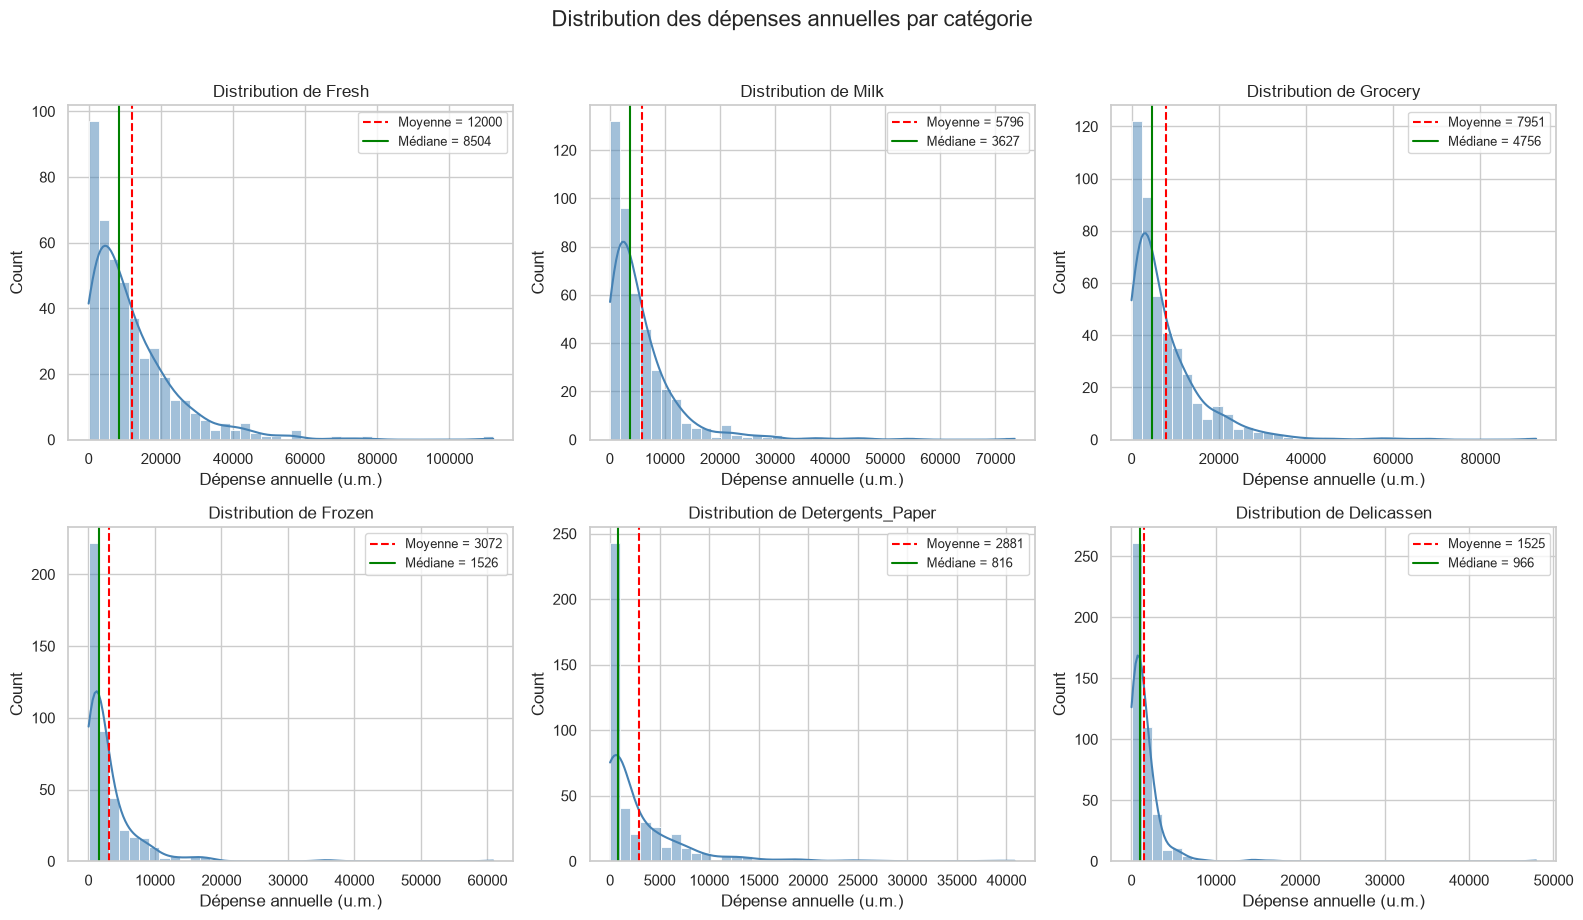

In [17]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, col in enumerate(SPEND_COLS):
    sns.histplot(df[col], bins=40, kde=True, ax=axes[i], color="steelblue")
    axes[i].axvline(df[col].mean(), color="red", linestyle="--", label=f"Moyenne = {df[col].mean():.0f}")
    axes[i].axvline(df[col].median(), color="green", linestyle="-", label=f"Médiane = {df[col].median():.0f}")
    axes[i].set_title(f"Distribution de {col}")
    axes[i].set_xlabel("Dépense annuelle (u.m.)")
    axes[i].legend(fontsize=9)

plt.suptitle("Distribution des dépenses annuelles par catégorie", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

In [18]:
# Coefficient d'asymétrie (skewness)
skew = df[SPEND_COLS].skew().sort_values(ascending=False).to_frame("Skewness")
skew["Interprétation"] = np.where(skew["Skewness"] > 1, "Forte asymétrie à droite",
                          np.where(skew["Skewness"] > 0.5, "Asymétrie modérée", "Quasi symétrique"))
skew

,Skewness,Interprétation
Delicassen,11.15,Forte asymétrie à droite
Frozen,5.91,Forte asymétrie à droite
Milk,4.05,Forte asymétrie à droite
Detergents_Paper,3.63,Forte asymétrie à droite
Grocery,3.59,Forte asymétrie à droite
Fresh,2.56,Forte asymétrie à droite


**Observations :**
- **Toutes les distributions sont fortement asymétriques à droite** : une grande concentration de clients aux faibles dépenses, et une longue « queue » vers les valeurs élevées. Sur chaque graphique, la moyenne (rouge) est décalée à droite de la médiane (verte).
- Le skewness confirme ce constat : il est **supérieur à 2 pour toutes les variables**, allant de 2,56 (`Fresh`) à **11,15 (`Delicassen`)**, dont la distribution est écrasée par quelques valeurs extrêmes. `Frozen` (5,91) et `Milk` (4,05) sont aussi très asymétriques.
- Ces distributions sont **loin d'une loi normale**.

**Conséquence pour la suite :** les algorithmes basés sur les distances (comme K-Means) seraient dominés par les quelques gros clients. Une **transformation logarithmique** sera nécessaire pour réduire l'asymétrie.

### 4.2 Boxplots
**Pourquoi :** les boxplots résument chaque distribution (médiane, quartiles) et font apparaître les **valeurs extrêmes**, représentées par les points au-delà des « moustaches » (1,5 × l'écart interquartile).

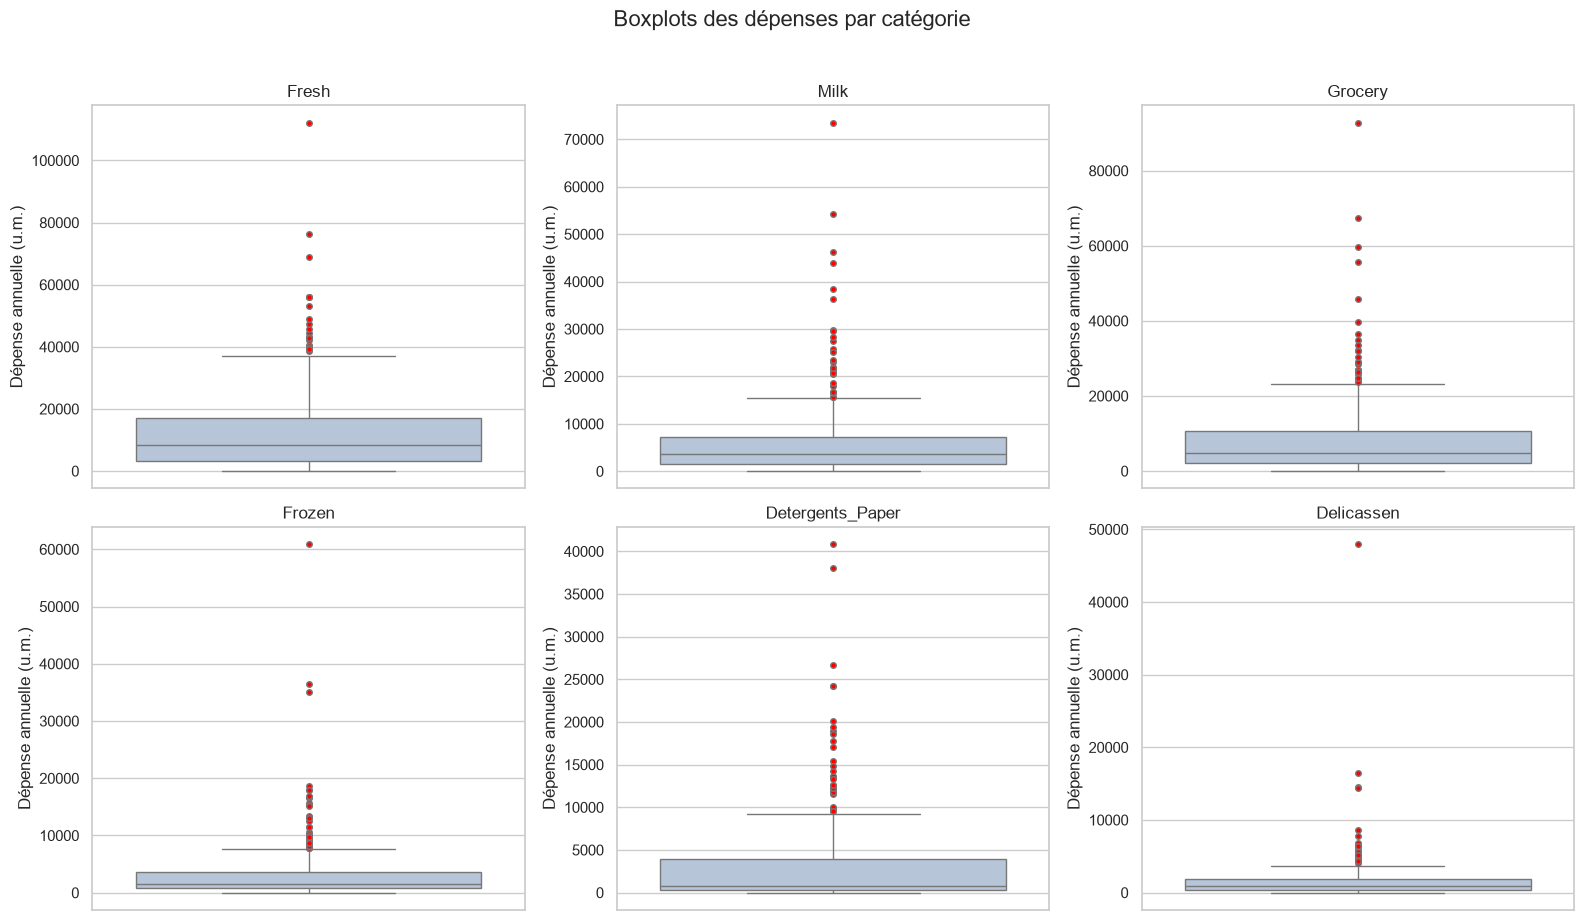

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, col in enumerate(SPEND_COLS):
    sns.boxplot(y=df[col], ax=axes[i], color="lightsteelblue", flierprops={"marker": "o", "markerfacecolor": "red", "markersize": 4})
    axes[i].set_title(col)
    axes[i].set_ylabel("Dépense annuelle (u.m.)")

plt.suptitle("Boxplots des dépenses par catégorie", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

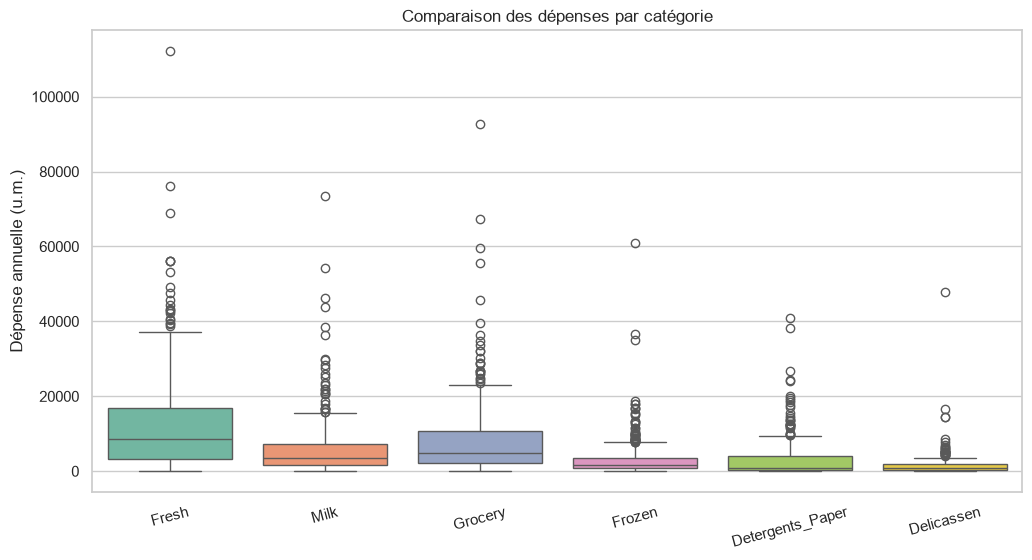

In [20]:
# Vue comparative de toutes les catégories sur une même échelle
plt.figure(figsize=(12, 6))
sns.boxplot(data=df[SPEND_COLS], palette="Set2")
plt.title("Comparaison des dépenses par catégorie")
plt.ylabel("Dépense annuelle (u.m.)")
plt.xticks(rotation=15)
plt.show()

**Observations :**
- Chaque catégorie présente de **nombreuses valeurs extrêmes** au-dessus de la moustache supérieure, et aucune en dessous. Cela confirme l'asymétrie à droite.
- Les « boîtes » (50 % centraux des clients) sont très **écrasées** par rapport à l'étendue totale : la grande majorité des clients a des dépenses modestes.
- Sur l'échelle commune, `Fresh` a la boîte la plus haute et la plus large (médiane ≈ 8 500), tandis que `Detergents_Paper` et `Delicassen` ont des médianes bien plus faibles (≈ 800 à 1 000).
- Les échelles sont **très différentes d'une catégorie à l'autre** : une **standardisation** sera indispensable pour que chaque variable ait le même poids dans le clustering.

Ces valeurs extrêmes seront analysées en détail dans la section « Anomalies ».

### 4.3 Distributions selon le canal de vente
**Pourquoi :** on compare les dépenses des clients **Horeca** et **Retail** pour vérifier si leur comportement d'achat diffère. Si c'est le cas, c'est un signe qu'il existe des **groupes naturels** dans les données, ce qui est encourageant pour le clustering.

*Note :* on utilise une **échelle logarithmique** sur l'axe vertical pour que les différences restent lisibles malgré les valeurs extrêmes.

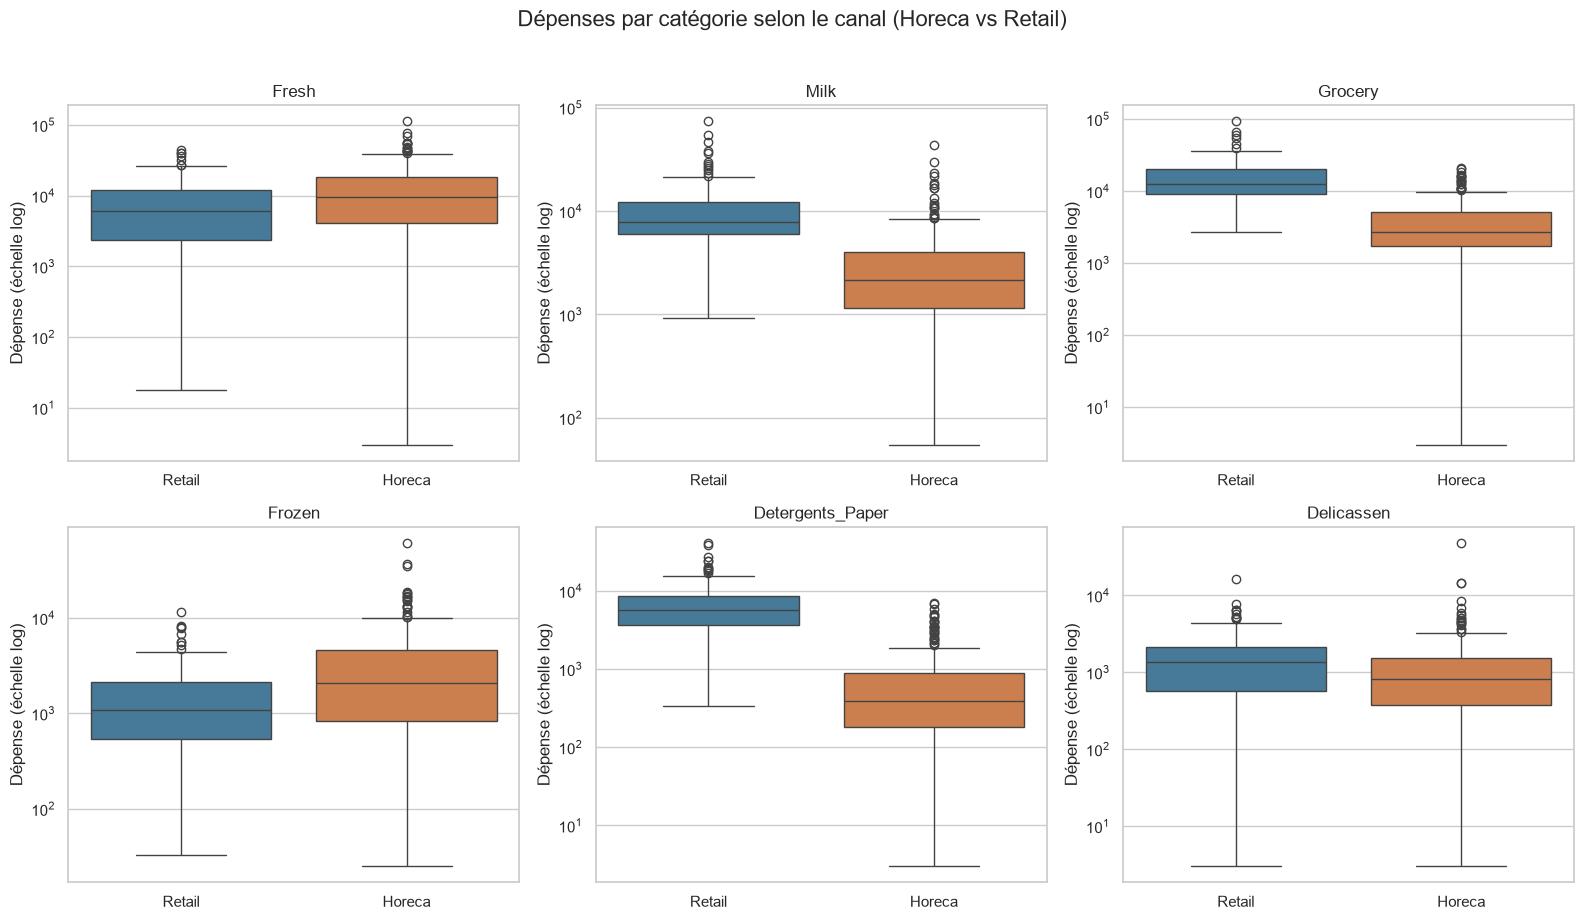

In [21]:
df_plot = df.copy()
df_plot["Channel_label"] = df_plot["Channel"].map(channel_map)

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, col in enumerate(SPEND_COLS):
    sns.boxplot(data=df_plot, x="Channel_label", y=col, ax=axes[i], palette={"Horeca": "#E07B39", "Retail": "#3A7CA5"})
    axes[i].set_yscale("log")
    axes[i].set_title(col)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("Dépense (échelle log)")

plt.suptitle("Dépenses par catégorie selon le canal (Horeca vs Retail)", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

In [22]:
# Dépenses médianes par canal
mediane_canal = df_plot.groupby("Channel_label")[SPEND_COLS].median().T
mediane_canal["Ratio Retail/Horeca"] = mediane_canal["Retail"] / mediane_canal["Horeca"]
mediane_canal.round(2)

Channel_label,Horeca,Retail,Ratio Retail/Horeca
Fresh,9581.50,5993.50,0.63
Milk,2157.00,7812.00,3.62
Grocery,2684.00,12390.00,4.62
Frozen,2057.50,1081.00,0.53
Detergents_Paper,385.50,5614.50,14.56
Delicassen,821.00,1350.00,1.64


**Observations :** les deux canaux ont des profils d'achat **très différents** :
- Les clients **Retail** dépensent beaucoup plus en **`Grocery`** (médiane ≈ 12 400 contre ≈ 2 700, soit ×4,6), en **`Detergents_Paper`** (≈ 5 600 contre ≈ 390, soit **×14,6**) et en **`Milk`** (≈ 7 800 contre ≈ 2 150, soit ×3,6). Ce sont des produits revendus en rayon.
- Les clients **Horeca** dépensent davantage en **`Fresh`** (≈ 9 600 contre ≈ 6 000) et en **`Frozen`** (≈ 2 060 contre ≈ 1 080). Ce sont des produits destinés à la cuisine et à la préparation de repas.
- `Delicassen` est un peu plus élevé chez les Retail, mais l'écart reste modéré.

Cette différence nette laisse penser que le clustering devrait faire émerger au moins une séparation de type **« profil restauration »** vs **« profil commerce de détail »**.

### 4.4 Corrélations entre variables
**Pourquoi :** la matrice de corrélation mesure la force des liens linéaires entre les catégories de dépenses. Des variables très corrélées apportent une **information redondante**, ce qui justifiera plus tard une réduction de dimension (ACP).

On calcule deux coefficients :
- **Pearson** : relation linéaire, sensible aux valeurs extrêmes ;
- **Spearman** : basé sur les rangs, donc **plus robuste** aux valeurs extrêmes et aux distributions asymétriques comme les nôtres.

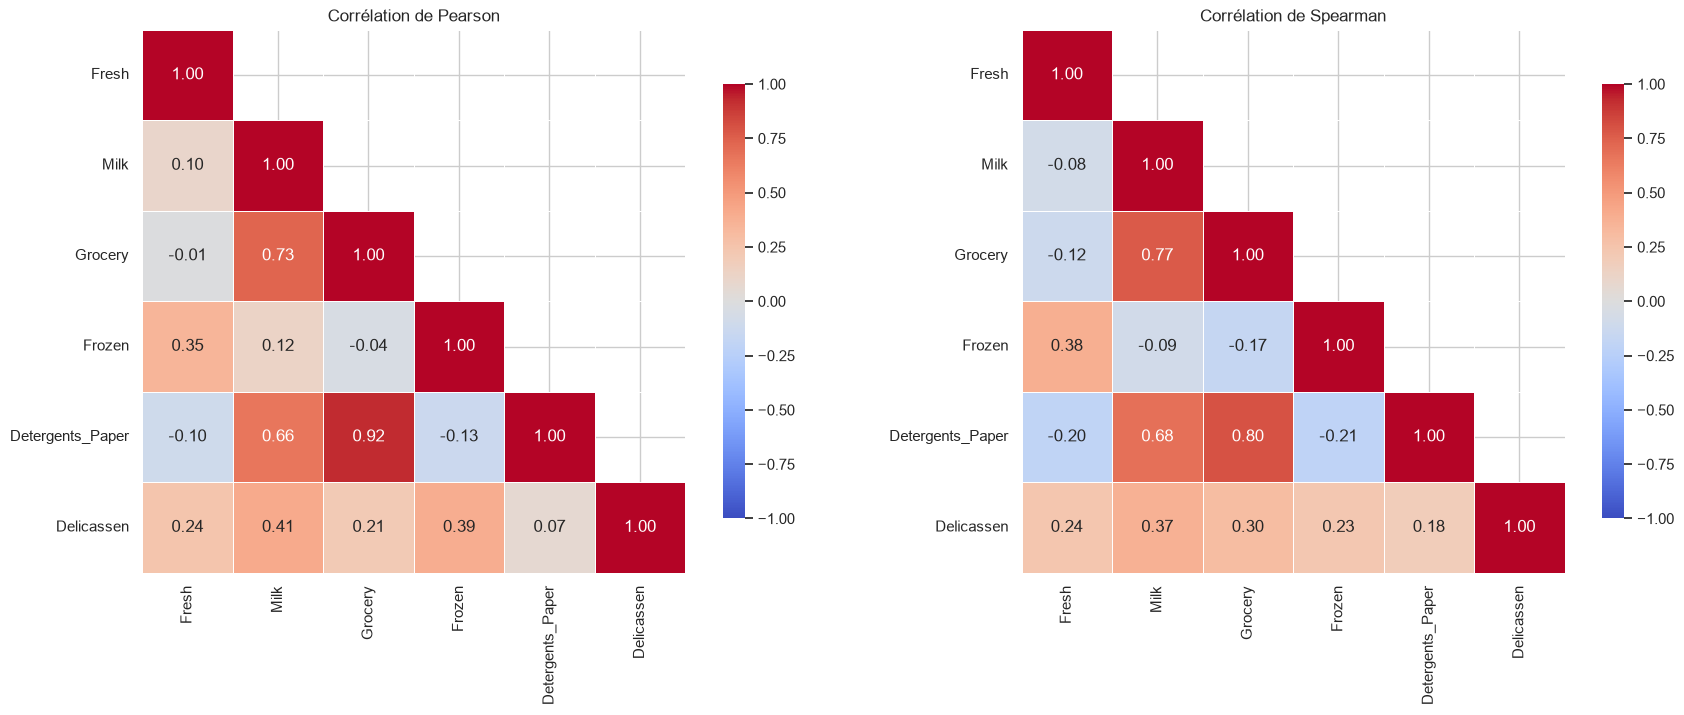

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
mask = np.triu(np.ones((len(SPEND_COLS), len(SPEND_COLS)), dtype=bool), k=1)

for ax, method in zip(axes, ["pearson", "spearman"]):
    corr = df[SPEND_COLS].corr(method=method)
    sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
                square=True, linewidths=0.5, ax=ax, cbar_kws={"shrink": 0.8})
    ax.set_title(f"Corrélation de {method.capitalize()}")

plt.tight_layout()
plt.show()

In [24]:
# Classement des paires de variables les plus corrélées (Spearman)
corr_s = df[SPEND_COLS].corr(method="spearman")
paires = (corr_s.where(np.triu(np.ones(corr_s.shape, dtype=bool), k=1))
                .stack()
                .sort_values(key=abs, ascending=False)
                .to_frame("Corrélation Spearman"))
paires.head(8)

Corrélation Spearman
Grocery Detergents_Paper                  0.80
Milk    Grocery                           0.77
        Detergents_Paper                  0.68
Fresh   Frozen                            0.38
Milk    Delicassen                        0.37
Grocery Delicassen                        0.30
Fresh   Delicassen                        0.24
Frozen  Delicassen                        0.23

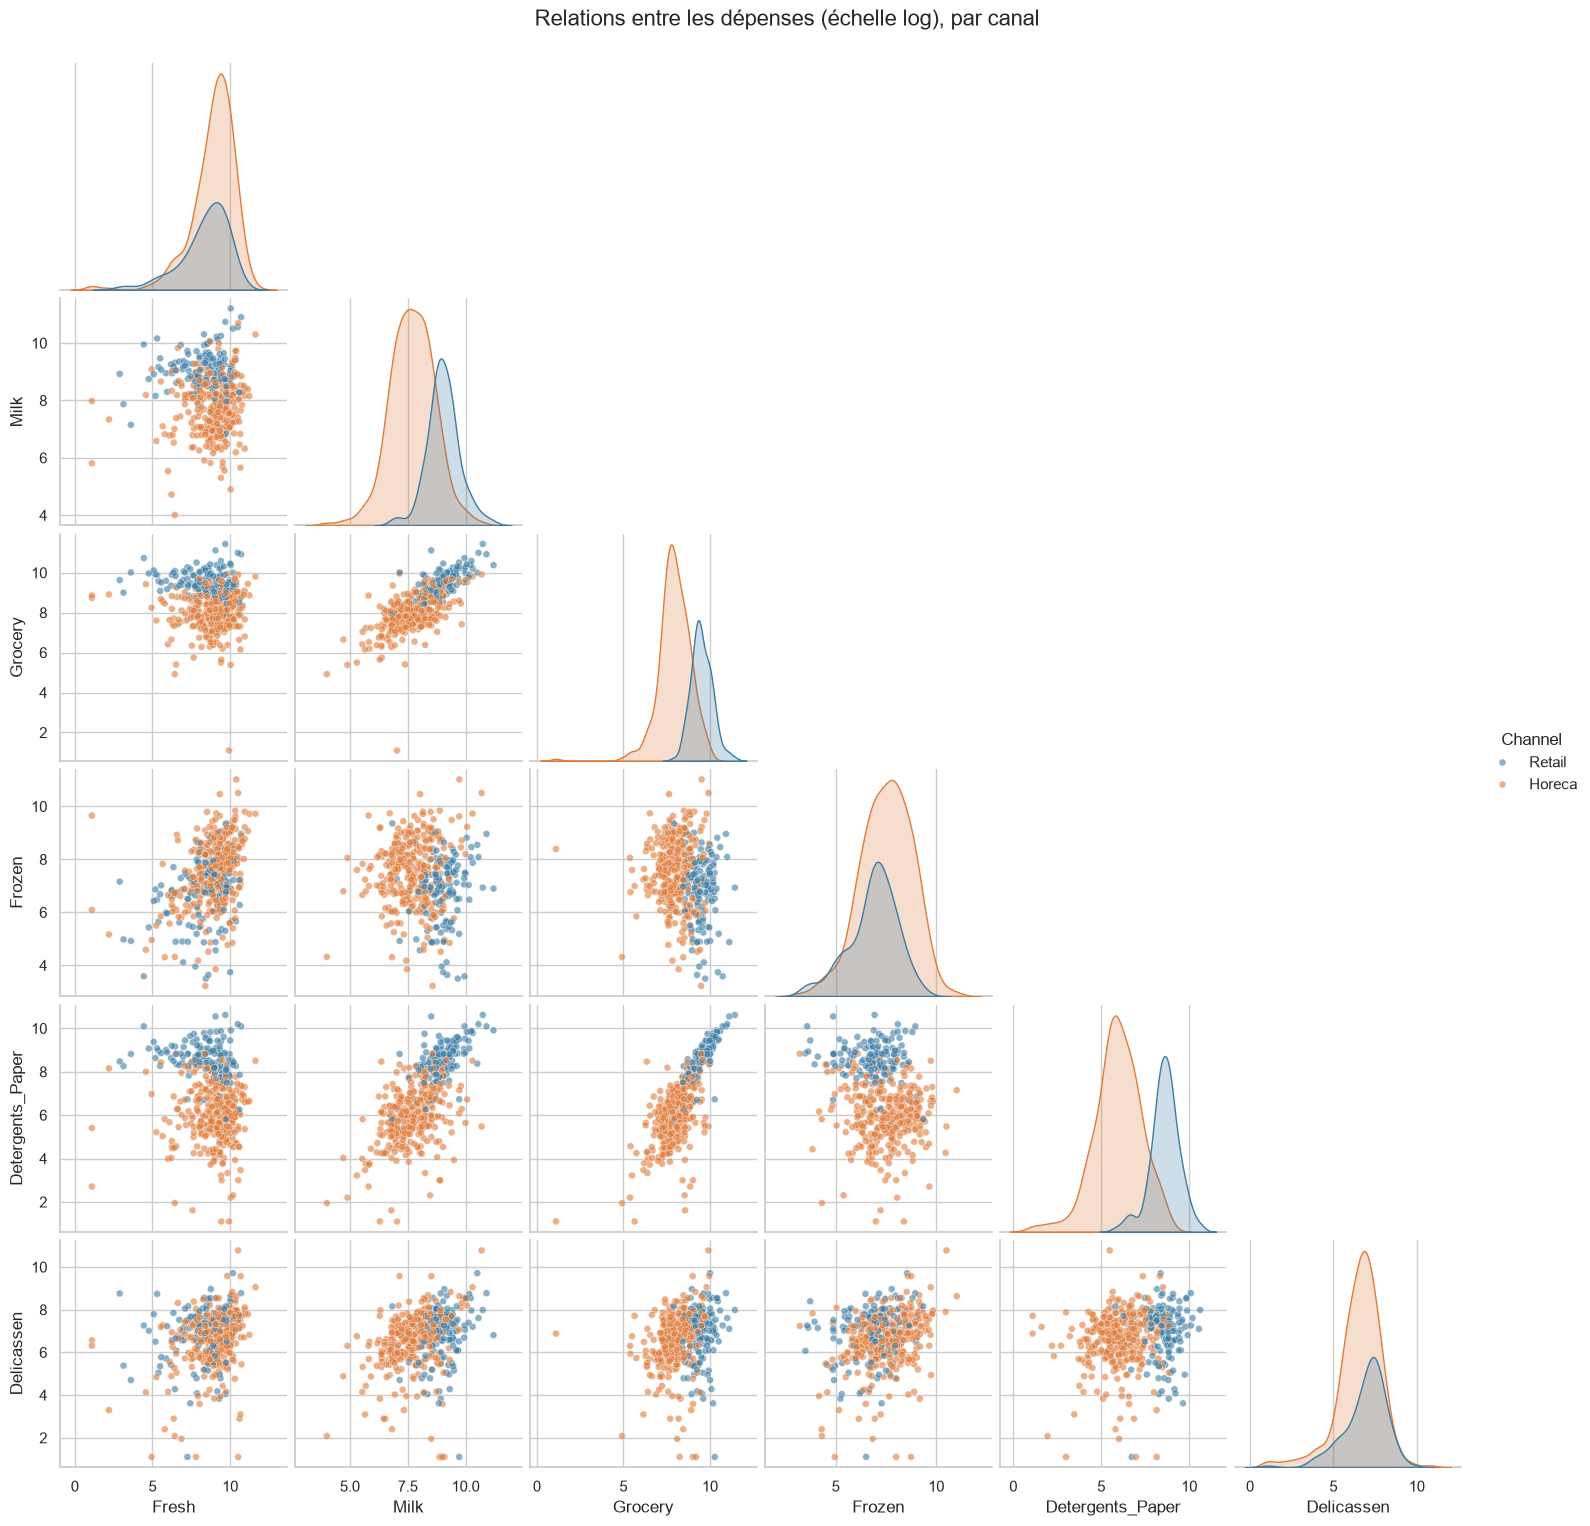

In [25]:
# Pairplot : relations deux à deux, coloré par canal (échelle log pour la lisibilité)
df_log_plot = np.log(df[SPEND_COLS]).assign(Channel=df["Channel"].map(channel_map))

g = sns.pairplot(df_log_plot, hue="Channel", palette={"Horeca": "#E07B39", "Retail": "#3A7CA5"},
                 diag_kind="kde", plot_kws={"alpha": 0.6, "s": 25}, corner=True)
g.figure.suptitle("Relations entre les dépenses (échelle log), par canal", fontsize=16, y=1.02)
plt.show()

**Observations :**
- **Groupe fortement corrélé : `Grocery`, `Detergents_Paper` et `Milk`**
  - `Grocery` ↔ `Detergents_Paper` : **0,92** (Pearson), 0,80 (Spearman). C'est la corrélation la plus forte du dataset.
  - `Milk` ↔ `Grocery` : 0,73 / 0,77.
  - `Milk` ↔ `Detergents_Paper` : 0,66 / 0,68.
  
  Ces trois catégories évoluent ensemble : elles correspondent au **panier type d'un commerce de détail** (produits revendus en rayon).
- **Lien modéré entre `Fresh` et `Frozen`** (≈ 0,35 à 0,38) : panier plutôt orienté **restauration**.
- **`Delicassen`** est faiblement à modérément lié à plusieurs catégories (0,2 à 0,4) : c'est un achat plutôt transversal.
- **`Fresh` et `Frozen` sont légèrement corrélés négativement** au groupe Grocery/Detergents/Milk (Spearman jusqu'à -0,21) : les clients qui achètent beaucoup de l'un achètent plutôt moins de l'autre.
- L'écart entre Pearson (0,92) et Spearman (0,80) pour Grocery/Detergents montre que **les valeurs extrêmes gonflent la corrélation linéaire** : Spearman est plus fiable ici.
- Le **pairplot** montre visuellement que les clients Retail (bleu) et Horeca (orange) se séparent bien sur les axes `Grocery`, `Milk` et `Detergents_Paper`, et beaucoup moins sur `Fresh`, `Frozen` et `Delicassen`.

**Conséquences :**
1. La redondance entre Grocery, Milk et Detergents_Paper justifie l'usage d'une **ACP** : ces trois variables pourront être résumées par un même axe.
2. Les données semblent s'organiser autour de **deux grands profils d'achat** (« épicerie/hygiène » vs « frais/surgelés »), cohérents avec la distinction Horeca/Retail.

### Etape : 5 Anomalies et observations intéressantes

#### 5.1 Détection des valeurs aberrantes (méthode IQR de Tukey)
**Pourquoi :** les boxplots ont montré de nombreuses valeurs extrêmes. On les quantifie avec la **règle de Tukey** : une valeur est considérée comme aberrante si elle sort de l'intervalle

$$[Q_1 - 1{,}5 \times IQR \; ; \; Q_3 + 1{,}5 \times IQR] \quad \text{avec} \quad IQR = Q_3 - Q_1$$

C'est la règle utilisée par les moustaches des boxplots. L'objectif n'est pas de supprimer ces clients à l'aveugle, mais de **comprendre qui ils sont** avant de décider comment les traiter.

In [26]:
def detect_outliers_iqr(data, cols, k=1.5):
    """Retourne un DataFrame booléen (True = valeur aberrante) et les bornes de Tukey."""
    q1 = data[cols].quantile(0.25)
    q3 = data[cols].quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - k * iqr, q3 + k * iqr
    mask = (data[cols] < lower) | (data[cols] > upper)
    bounds = pd.DataFrame({"Borne basse": lower, "Borne haute": upper})
    return mask, bounds

outliers_mask, bounds = detect_outliers_iqr(df, SPEND_COLS)

resume = bounds.copy()
resume["Nb aberrants"] = outliers_mask.sum()
resume["% clients"] = (outliers_mask.mean() * 100).round(1)
resume

,Borne basse,Borne haute,Nb aberrants,% clients
Fresh,-17581.25,37642.75,20,4.50
Milk,-6952.88,15676.12,28,6.40
Grocery,-10601.12,23409.88,24,5.50
Frozen,-3475.75,7772.25,43,9.80
Detergents_Paper,-5241.12,9419.88,30,6.80
Delicassen,-1709.75,3938.25,27,6.10


In [27]:
# Combien de variables aberrantes par client ?
nb_outliers_client = outliers_mask.sum(axis=1)

print(f"Clients avec au moins 1 valeur aberrante : {(nb_outliers_client > 0).sum()} "
      f"({(nb_outliers_client > 0).mean() * 100:.1f} % des clients)\n")
print("Répartition selon le nombre de variables aberrantes :")
print(nb_outliers_client.value_counts().sort_index().rename_axis("Nb variables").to_frame("Nb clients"))

# Poids de ces clients dans le chiffre d'affaires
df_total = df[SPEND_COLS].sum(axis=1)
part_ca = df_total[nb_outliers_client > 0].sum() / df_total.sum() * 100
print(f"\nPart des dépenses totales réalisée par ces clients : {part_ca:.1f} %")

print("\nCanal des clients avec au moins une valeur aberrante :")
print(df.loc[nb_outliers_client > 0, "Channel"].map(channel_map).value_counts())

Clients avec au moins 1 valeur aberrante : 108 (24.5 % des clients)

Répartition selon le nombre de variables aberrantes :
              Nb clients
Nb variables            
0                    332
1                     67
2                     24
3                     13
4                      3
6                      1

Part des dépenses totales réalisée par ces clients : 44.7 %

Canal des clients avec au moins une valeur aberrante :
Channel
Horeca    61
Retail    47
Name: count, dtype: int64


**Observations :**
- Toutes les valeurs aberrantes détectées sont **au-dessus de la borne haute** (la borne basse est négative, donc impossible à franchir). Ce sont des clients qui dépensent **beaucoup plus** que la moyenne.
- `Frozen` est la variable avec le plus de valeurs aberrantes (43), suivie de `Detergents_Paper` (30) et `Milk` (28).
- Au total, **108 clients (24,5 %)** ont au moins une valeur aberrante. La plupart ne le sont que sur 1 variable (67 clients) ou 2 variables (24 clients).
- Ces 108 clients réalisent **44,7 % des dépenses totales** du grossiste.

**Point important :** supprimer tous ces clients reviendrait à retirer **un quart du dataset** et **près de la moitié du chiffre d'affaires**. Ce ne sont pas des erreurs, ce sont les **gros clients**, qui ont justement une grande valeur pour l'entreprise. La méthode IQR sur les données brutes est donc **trop sévère** à cause de l'asymétrie des distributions.

##### 5.2 Les clients les plus atypiques
**Pourquoi :** on identifie les clients extrêmes (valeur maximale de chaque catégorie, clients aberrants sur plusieurs catégories) pour vérifier s'ils sont **plausibles** et à quel profil ils correspondent.

In [28]:
# Client ayant la dépense maximale dans chaque catégorie
max_clients = pd.DataFrame({
    "ID client": [df[col].idxmax() for col in SPEND_COLS],
    "Valeur max": [df[col].max() for col in SPEND_COLS],
    "Canal": [channel_map[df.loc[df[col].idxmax(), "Channel"]] for col in SPEND_COLS]
}, index=SPEND_COLS)
max_clients

,ID client,Valeur max,Canal
Fresh,181,112151,Horeca
Milk,86,73498,Retail
Grocery,85,92780,Retail
Frozen,325,60869,Horeca
Detergents_Paper,85,40827,Retail
Delicassen,183,47943,Horeca


In [29]:
# Clients aberrants sur au moins 3 variables
multi_outliers = df[nb_outliers_client >= 3].copy()
multi_outliers["Canal"] = multi_outliers["Channel"].map(channel_map)
multi_outliers["Total"] = df_total[multi_outliers.index]
multi_outliers["Nb var. aberrantes"] = nb_outliers_client[multi_outliers.index]
multi_outliers.sort_values("Total", ascending=False)

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Canal,Total,Nb var. aberrantes
85,2,3,16117,46197,92780,1026,40827,2944,Retail,199891,3
47,2,3,44466,54259,55571,7782,24171,6465,Retail,192714,6
181,1,3,112151,29627,18148,16745,4948,8550,Horeca,190169,4
183,1,3,36847,43950,20170,36534,239,47943,Horeca,185683,3
61,2,3,35942,38369,59598,3254,26701,2017,Retail,165881,3
86,2,3,22925,73498,32114,987,20070,903,Retail,150497,3
325,1,2,32717,16784,13626,60869,1272,5609,Horeca,130877,3
211,2,1,12119,28326,39694,4736,19410,2870,Retail,107155,3
92,2,3,9198,27472,32034,3232,18906,5130,Retail,95972,4
251,2,1,6134,23133,33586,6746,18594,5121,Retail,93314,4


In [30]:
# Concentration du chiffre d'affaires
top10 = df_total.nlargest(int(len(df) * 0.10)).sum() / df_total.sum() * 100
print(f"Les 10 % des clients qui dépensent le plus réalisent {top10:.1f} % des dépenses totales.")
print("\nTop 5 des clients par dépense totale :")
display(df.assign(Total=df_total, Canal=df["Channel"].map(channel_map)).nlargest(5, "Total"))

Les 10 % des clients qui dépensent le plus réalisent 27.6 % des dépenses totales.

Top 5 des clients par dépense totale :


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Total,Canal
85,2,3,16117,46197,92780,1026,40827,2944,199891,Retail
47,2,3,44466,54259,55571,7782,24171,6465,192714,Retail
181,1,3,112151,29627,18148,16745,4948,8550,190169,Horeca
183,1,3,36847,43950,20170,36534,239,47943,185683,Horeca
61,2,3,35942,38369,59598,3254,26701,2017,165881,Retail


**Observations :**
- **17 clients** sont aberrants sur au moins 3 catégories, dont **14 sont Retail**. Ce sont pour la plupart de **gros commerces de détail** qui achètent massivement les produits du panier « épicerie » (`Grocery`, `Milk`, `Detergents_Paper`). Le client **n°47** est même aberrant sur **les 6 catégories**.
- Le client **n°85** détient à la fois le maximum de `Grocery` (92 780) et de `Detergents_Paper` (40 827), avec la plus forte dépense totale (≈ 200 000) : c'est un très grand distributeur.
- Trois clients **Horeca** se distinguent :
  - **n°181** : maximum de `Fresh` (112 151), sans doute un gros restaurant ou une chaîne d'hôtels ;
  - **n°183** : maximum de `Delicassen` (47 943) et forte dépense en `Frozen` (36 534), un profil traiteur ou hôtel haut de gamme ;
  - **n°325** : maximum de `Frozen` (60 869).
- Les **10 % de clients** qui dépensent le plus réalisent **27,6 % des dépenses totales** : il existe une concentration notable du chiffre d'affaires sur quelques gros comptes.

Ces profils sont **cohérents et plausibles** : ce sont des clients réels de grande taille, pas des erreurs de saisie. Ils pourraient même constituer un **segment « grands comptes »** à part entière.

### 5.3 Valeurs aberrantes après transformation logarithmique
**Pourquoi :** comme les distributions sont très asymétriques, la règle IQR appliquée aux données brutes signale surtout les gros clients. En appliquant la même règle aux données en **échelle logarithmique** (plus proches d'une distribution symétrique), on détecte les clients **réellement atypiques** par rapport à la structure des données.

In [31]:
df_log = np.log(df[SPEND_COLS])   # toutes les valeurs sont > 0, le log est bien défini

outliers_log_mask, _ = detect_outliers_iqr(df_log, SPEND_COLS)
nb_outliers_log = outliers_log_mask.sum(axis=1)

comparaison = pd.DataFrame({
    "Aberrants (brut)": outliers_mask.sum(),
    "Aberrants (log)": outliers_log_mask.sum()
})
display(comparaison)

print(f"Clients avec au moins 1 valeur aberrante : brut = {(nb_outliers_client > 0).sum()} | log = {(nb_outliers_log > 0).sum()}")
print(f"Clients aberrants sur au moins 2 variables (log) : {(nb_outliers_log >= 2).sum()}")

,Aberrants (brut),Aberrants (log)
Fresh,20,16
Milk,28,4
Grocery,24,2
Frozen,43,10
Detergents_Paper,30,2
Delicassen,27,14


Clients avec au moins 1 valeur aberrante : brut = 108 | log = 42
Clients aberrants sur au moins 2 variables (log) : 5


In [32]:
# Clients atypiques sur plusieurs variables en échelle log
atypiques = df[nb_outliers_log >= 2].copy()
atypiques["Canal"] = atypiques["Channel"].map(channel_map)
atypiques["Total"] = df_total[atypiques.index]
atypiques["Variables concernées"] = outliers_log_mask.loc[atypiques.index].apply(
    lambda row: ", ".join(row.index[row]), axis=1)
atypiques

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Canal,Total,Variables concernées
65,2,3,85,20959,45828,36,24231,1423,Retail,92562,"Fresh, Frozen"
66,1,3,9,1534,7417,175,3468,27,Horeca,12630,"Fresh, Delicassen"
75,1,3,20398,1137,3,4407,3,975,Horeca,26923,"Grocery, Detergents_Paper"
128,1,3,140,8847,3823,142,1062,3,Horeca,14017,"Fresh, Delicassen"
154,1,3,622,55,137,75,7,8,Horeca,904,"Milk, Grocery, Delicassen"


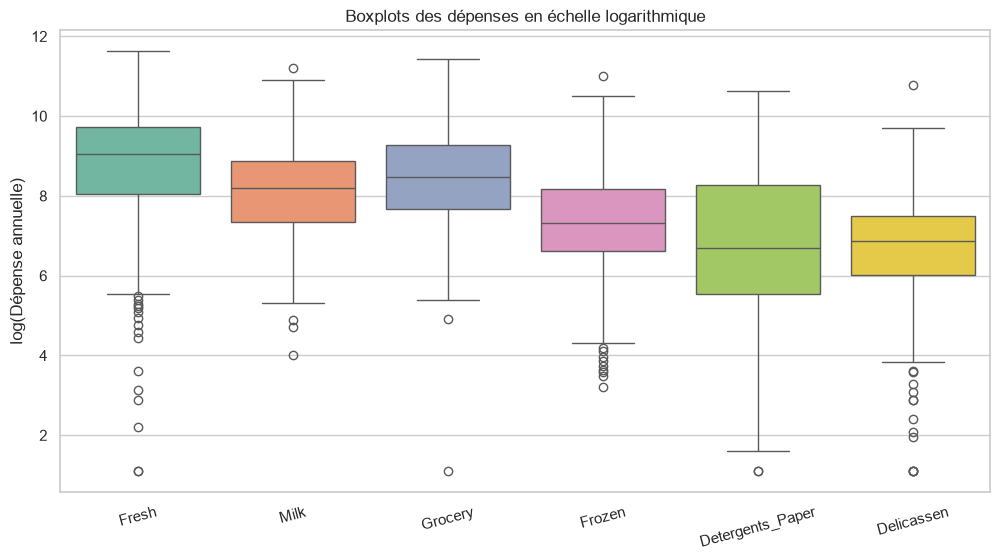

In [33]:
# Boxplots en échelle log : les anomalies apparaissent maintenant surtout vers le bas
plt.figure(figsize=(12, 6))
sns.boxplot(data=df_log, palette="Set2")
plt.title("Boxplots des dépenses en échelle logarithmique")
plt.ylabel("log(Dépense annuelle)")
plt.xticks(rotation=15)
plt.show()

**Observations :**
- Après transformation logarithmique, le nombre de clients concernés passe de **108 à 42**. Les gros clients ne sont plus considérés comme anormaux, car le log « rapproche » les grandes valeurs.
- Les anomalies restantes sont maintenant **majoritairement des valeurs anormalement basses** (`Fresh` : 16, `Delicassen` : 13, `Frozen` : 9), c'est-à-dire des clients qui n'achètent **presque pas** une catégorie.
- Seuls **5 clients** sont atypiques sur au moins 2 variables :
  - **n°154** : le plus petit client du dataset (dépense totale de **904** seulement, avec 7 en `Detergents_Paper` et 8 en `Delicassen`) ;
  - **n°75** : seulement **3** en `Grocery` et **3** en `Detergents_Paper`, alors qu'il dépense 20 398 en `Fresh`. Valeurs suspectes : erreur de saisie, ou client qui achète ces produits ailleurs ;
  - **n°66** : seulement **9** en `Fresh` et 27 en `Delicassen` ;
  - **n°128** : seulement 140 en `Fresh` et **3** en `Delicassen` ;
  - **n°65** : quasiment rien en `Fresh` (85) et en `Frozen` (36), mais de très gros achats en `Grocery` (45 828). C'est un commerce spécialisé.

Ces 5 clients ont des profils **incohérents ou extrêmement déséquilibrés**. En échelle log, leurs valeurs quasi nulles deviennent des points très isolés, qui risquent de **perturber le clustering**, notamment K-Means, très sensible aux points isolés.

### 5.4 Synthèse de l'analyse exploratoire (EDA)

**Qualité des données**
- 440 clients, 8 variables, **aucune valeur manquante, aucun doublon, aucune valeur négative**.
- `Channel` et `Region` sont des variables **catégorielles** codées en chiffres.

**Distributions**
- Les 6 variables de dépenses sont **fortement asymétriques à droite** (skewness de 2,6 à 11,2), avec des **échelles très différentes**.
- Les clients sont **très hétérogènes** (coefficient de variation ≥ 1) : il y a matière à segmenter.

**Relations entre variables**
- Forte corrélation entre **`Grocery`, `Detergents_Paper` et `Milk`** (jusqu'à 0,92) : panier « commerce de détail ».
- Lien modéré entre **`Fresh` et `Frozen`** : panier « restauration ».
- Les clients **Horeca** et **Retail** ont des profils d'achat nettement différents, ce qui laisse espérer des **groupes naturels**.

**Anomalies**
- Sur données brutes, **108 clients** sont aberrants. Ce sont surtout de **gros clients légitimes** (44,7 % du chiffre d'affaires), à **conserver**.
- Après passage au log, **5 clients** (n°65, 66, 75, 128, 154) restent atypiques sur plusieurs variables, avec des valeurs quasi nulles ou suspectes.

### 5.5 Recommandations pour le prétraitement
1. **Transformation logarithmique** des dépenses, pour réduire l'asymétrie et l'influence des gros clients.
2. **Standardisation** des variables, pour donner le même poids à chaque catégorie dans le calcul des distances.
3. **Ne pas supprimer massivement les valeurs aberrantes brutes** : ce sont des clients réels et importants.
4. **Étudier le retrait des 5 clients atypiques** identifiés en échelle log, et comparer les résultats du clustering avec et sans eux pour mesurer leur influence.
5. **Exclure `Channel` et `Region` du clustering** et les conserver pour l'interprétation et la validation.
6. Envisager une **ACP** pour exploiter la redondance entre `Grocery`, `Milk` et `Detergents_Paper`, et pour visualiser les clusters en 2D.

### Étape 6 : Nettoyage et préparation des données (Data Preprocessing)

**Objectif :** transformer les données brutes en un dataset **propre, cohérent et exploitable**, prêt pour le Feature Engineering.

**Principes de travail :**
- on travaille sur une **copie** (`df_clean`) : `df` reste intact pour comparer les données avant et après nettoyage ;
- on **conserve l'index d'origine** comme identifiant client (`ID_client`) : les clients n°65, 75, 154… restent identifiables tout au long du projet ;
- chaque décision est consignée dans un **journal de nettoyage**, pour rendre le traitement traçable et reproductible.

**Missions :**
1. Traiter les valeurs manquantes.
2. Identifier et supprimer les doublons pertinents.
3. Traiter les valeurs aberrantes (outliers).
4. Identifier les transactions incohérentes.
5. Sélectionner les variables pertinentes pour la segmentation.
6. Vérifier la qualité des données après nettoyage.
7. Préparer les données pour les étapes suivantes.

In [34]:
# Copie de travail : df reste intact pour les comparaisons avant / après
df_clean = df.copy()
df_clean.index.name = "ID_client"

# Journal de nettoyage : trace chaque opération et son effet sur le nombre de lignes
journal = []

def log_etape(etape, decision, avant, apres):
    journal.append({"Étape": etape, "Décision": decision,
                    "Lignes avant": avant, "Lignes après": apres,
                    "Lignes retirées": avant - apres})

print(f"Dataset de départ : {df_clean.shape[0]} clients x {df_clean.shape[1]} variables")

Dataset de départ : 440 clients x 8 variables


#### 6.1 Traitement des valeurs manquantes
**Pourquoi :** les algorithmes de clustering de scikit-learn (K-Means, CAH, GMM) **n'acceptent pas les valeurs manquantes**. On vérifie deux types de manquants :
- les manquants **explicites** (`NaN`) ;
- les manquants **« déguisés »** (`"?"`, `"NA"`, chaîne vide…), qui forceraient pandas à lire une colonne numérique comme du texte.

**Stratégie prévue si des manquants sont trouvés :**
- variables de dépenses : imputation par la **médiane**, robuste à l'asymétrie (la moyenne serait tirée vers le haut par les gros clients) ;
- variables catégorielles : imputation par le **mode** (modalité la plus fréquente).

In [35]:
# 1) Valeurs manquantes explicites (NaN)
nb_manquants = df_clean.isnull().sum()
print("Valeurs manquantes par variable :")
display(nb_manquants.to_frame("Nb manquants").T)

# 2) Valeurs manquantes "déguisées" : une colonne non numérique trahirait du texte ("?", "NA", "")
non_numeriques = [c for c in df_clean.columns if not pd.api.types.is_numeric_dtype(df_clean[c])]
print("Colonnes non numériques :", non_numeriques if non_numeriques else "aucune")

# 3) Traitement, appliqué seulement si nécessaire
avant = len(df_clean)
if nb_manquants.sum() > 0:
    for col in SPEND_COLS:
        df_clean[col] = df_clean[col].fillna(df_clean[col].median())   # médiane : robuste à l'asymétrie
    for col in CAT_COLS:
        df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])  # mode pour les catégorielles
    decision = "Imputation : médiane (dépenses), mode (catégorielles)"
else:
    decision = "Aucune valeur manquante : aucun traitement"

log_etape("1. Valeurs manquantes", decision, avant, len(df_clean))
print("\nDécision :", decision)

Valeurs manquantes par variable :


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Nb manquants,0,0,0,0,0,0,0,0


Colonnes non numériques : aucune

Décision : Aucune valeur manquante : aucun traitement


**Observation :** aucune valeur manquante, ni explicite ni déguisée : les 8 colonnes sont bien numériques (`int64`). Aucune imputation n'est nécessaire.

Le code d'imputation est conservé : il rend le traitement **robuste** si le notebook est réexécuté sur une nouvelle extraction de données incomplète.

#### 6.2 Identification et suppression des doublons
**Pourquoi :** un client présent deux fois compte double. Il prend un **poids artificiel** dans le calcul des centres de clusters et peut créer un faux petit groupe.

On distingue deux niveaux :
- **doublons exacts** (les 8 variables identiques) : le fichier n'a pas d'identifiant client, mais avec 6 montants continus, la probabilité que deux clients différents aient exactement les mêmes dépenses est quasi nulle. Un doublon exact serait donc une **double saisie**, à supprimer ;
- **doublons sur les dépenses seules** (même profil d'achat, mais canal ou région différents) : c'est une **incohérence potentielle** (le même client enregistré avec deux canaux), à examiner au cas par cas plutôt qu'à supprimer automatiquement.

In [36]:
dup_exacts = df_clean.duplicated(keep="first")                      # True pour la 2e occurrence et les suivantes
dup_depenses = df_clean.duplicated(subset=SPEND_COLS, keep=False)   # True pour toutes les occurrences

print(f"Doublons exacts (8 variables identiques)       : {dup_exacts.sum()}")
print(f"Doublons sur les 6 dépenses (profil identique) : {dup_depenses.sum()}")

if dup_depenses.any():
    display(df_clean[dup_depenses].sort_values(SPEND_COLS))

avant = len(df_clean)
df_clean = df_clean[~dup_exacts]
log_etape("2. Doublons", f"Suppression des doublons exacts ({dup_exacts.sum()})", avant, len(df_clean))

Doublons exacts (8 variables identiques)       : 0
Doublons sur les 6 dépenses (profil identique) : 0


**Observation :** le dataset ne contient **aucun doublon exact** et **aucun doublon sur les dépenses**. Chaque ligne correspond donc à un client distinct. Aucune ligne n'est supprimée.

#### 6.3 Traitement des valeurs aberrantes (outliers)
**Pourquoi :** l'EDA (étape 5) a montré deux types de valeurs extrêmes, qui n'appellent pas le même traitement :
- **en échelle brute**, 108 clients sont aberrants selon la règle IQR. Ce sont surtout de **gros clients légitimes**, qui réalisent 44,7 % du chiffre d'affaires ;
- **en échelle log**, quelques clients restent isolés à cause de valeurs **quasi nulles** sur certaines catégories.

**Options possibles :**

| Méthode | Effet | Adaptée ici ? |
|---|---|---|
| Suppression (IQR brute) | Retire 1/4 des clients et près de la moitié du CA | **Non** : on perdrait les grands comptes |
| Plafonnement (winsorisation) | Ramène les valeurs extrêmes à un seuil | **Non** : efface l'information « grand compte » et écrase des écarts réels |
| Transformation log | Réduit l'influence des grandes valeurs sans rien supprimer | **Oui**, appliquée au Feature Engineering |
| Suppression ciblée | Retire uniquement les points isolés et incohérents | **Oui**, après vérification (6.4) |

**Décision :** on **conserve tous les gros clients**. Leur influence sera neutralisée par la transformation logarithmique. Seuls les clients atypiques **en échelle log sur au moins 2 variables** sont retenus comme **candidats** à la suppression. Leur cohérence est examinée en 6.4.

In [37]:
# Détection en échelle brute et en échelle log, sur le dataset en cours de nettoyage
df_clean_log = np.log(df_clean[SPEND_COLS])          # toutes les dépenses sont > 0
mask_brut, _ = detect_outliers_iqr(df_clean, SPEND_COLS)
mask_log, bornes_log = detect_outliers_iqr(df_clean_log, SPEND_COLS)

synthese_outliers = pd.DataFrame({
    "Aberrants (brut)": mask_brut.sum(),
    "Aberrants (log)": mask_log.sum(),
    "dont valeurs basses (log)": (df_clean_log < bornes_log["Borne basse"]).sum(),
    "Seuil bas en log (u.m.)": np.exp(bornes_log["Borne basse"]).round(0),
})
display(synthese_outliers)

grands_comptes = mask_brut.any(axis=1) & ~mask_log.any(axis=1)
nb_aberr_log = mask_log.sum(axis=1)
candidats_outliers = nb_aberr_log[nb_aberr_log >= 2].index.tolist()

print(f"Clients aberrants en brut uniquement (grands comptes conservés) : {grands_comptes.sum()}")
print(f"Clients atypiques en échelle log sur >= 2 variables (candidats) : {candidats_outliers}")

log_etape("3. Valeurs aberrantes", "Grands comptes conservés (traités par log au FE)", len(df_clean), len(df_clean))

,Aberrants (brut),Aberrants (log),dont valeurs basses (log),Seuil bas en log (u.m.)
Fresh,20,16,16,248.00
Milk,28,4,3,151.00
Grocery,24,2,2,196.00
Frozen,43,10,9,71.00
Detergents_Paper,30,2,2,4.00
Delicassen,27,14,13,43.00


Clients aberrants en brut uniquement (grands comptes conservés) : 94
Clients atypiques en échelle log sur >= 2 variables (candidats) : [65, 66, 75, 128, 154]


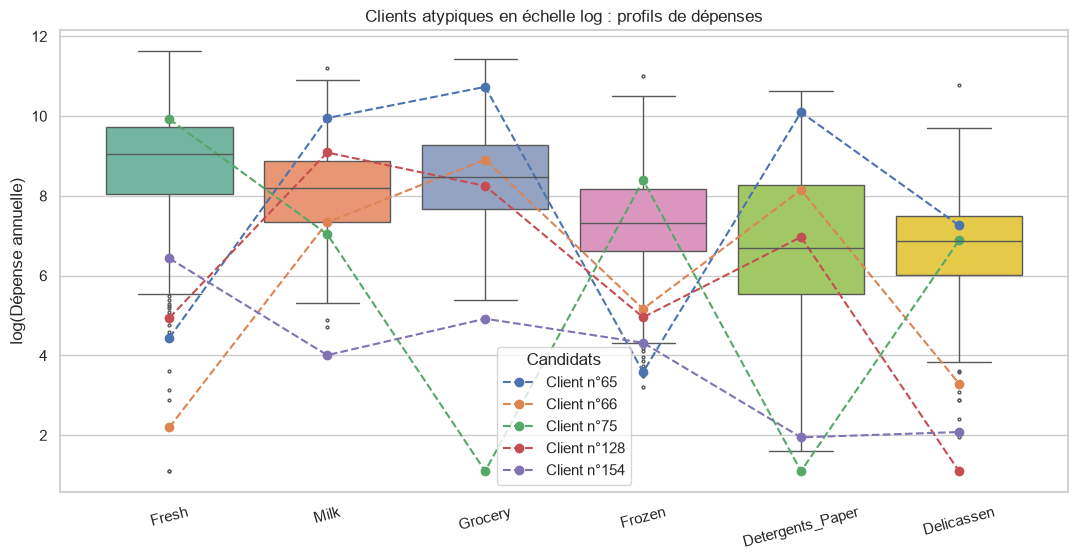

In [38]:
# Profil des candidats dans les distributions en échelle log
fig, ax = plt.subplots(figsize=(13, 6))
sns.boxplot(data=df_clean_log, palette="Set2", ax=ax, fliersize=2)
for idx in candidats_outliers:
    ax.plot(range(len(SPEND_COLS)), df_clean_log.loc[idx], marker="o", linestyle="--",
            linewidth=1.5, label=f"Client n°{idx}")
ax.set_title("Clients atypiques en échelle log : profils de dépenses")
ax.set_ylabel("log(Dépense annuelle)")
ax.legend(title="Candidats")
plt.xticks(rotation=15)
plt.show()

**Observations :**
- Sur les 108 clients aberrants en échelle brute, **94 ne le sont plus du tout en échelle log**. Ce sont des **grands comptes** dont les montants sont élevés mais cohérents avec la structure des données. Ils sont **conservés**.
- En échelle log, les anomalies sont surtout des **valeurs basses**. Les seuils bas sont par exemple d'environ 248 u.m./an pour `Fresh`, 71 pour `Frozen` et 43 pour `Delicassen`.
- **5 clients** sont atypiques sur au moins 2 variables : **n°65, 66, 75, 128 et 154**, les mêmes qu'à l'étape 5. Sur le graphique, leurs profils plongent nettement sous les moustaches pour certaines catégories : ce sont des **points isolés** qui risquent de tirer les centres de clusters.

Aucune ligne n'est supprimée à ce stade. Avant de décider, on vérifie en 6.4 si ces valeurs sont **plausibles** ou **incohérentes**.

#### 6.4 Identification des transactions incohérentes
**Pourquoi :** chaque ligne agrège les **transactions d'un client sur une année**. Certaines valeurs peuvent être impossibles ou très suspectes (erreur de saisie, mauvaise unité, client mal enregistré). Elles fausseraient la segmentation.

On applique deux familles de règles :

| Type | Règle | Traitement |
|---|---|---|
| **Règle dure** (valeur impossible) | Dépense négative | Suppression |
| | Dépense totale nulle (client sans aucun achat) | Suppression |
| | Code `Channel` hors de {1, 2} ou `Region` hors de {1, 2, 3} | Suppression |
| **Règle souple** (valeur suspecte) | Montant **quasi nul** sur une catégorie (≤ 10 u.m. par an, soit moins de 1 u.m. par mois) | Examen |
| | Profil **atypique en log sur ≥ 2 variables** (6.3) | Examen |

Un montant de 3 u.m. sur une année entière ne correspond même pas à une seule vraie commande chez un grossiste. C'est le signe d'une erreur de saisie, ou d'un client qui achète cette catégorie ailleurs.

In [39]:
SEUIL_QUASI_NUL = 10   # u.m. par an, soit moins de 1 u.m. par mois

regles = pd.DataFrame(index=df_clean.index)
# --- Règles dures : valeurs impossibles ---
regles["Dépense négative"]     = (df_clean[SPEND_COLS] < 0).any(axis=1)
regles["Dépense totale nulle"] = df_clean[SPEND_COLS].sum(axis=1) == 0
regles["Channel invalide"]     = ~df_clean["Channel"].isin(list(channel_map))
regles["Region invalide"]      = ~df_clean["Region"].isin(list(region_map))
# --- Règles souples : valeurs suspectes ---
regles["Montant quasi nul"]       = (df_clean[SPEND_COLS] <= SEUIL_QUASI_NUL).any(axis=1)
regles["Atypique log (>=2 var.)"] = regles.index.isin(candidats_outliers)

REGLES_DURES = ["Dépense négative", "Dépense totale nulle", "Channel invalide", "Region invalide"]
regles.sum().to_frame("Nb clients concernés")

,Nb clients concernés
Dépense négative,0
Dépense totale nulle,0
Channel invalide,0
Region invalide,0
Montant quasi nul,14
Atypique log (>=2 var.),5


In [40]:
# Détail des clients suspects (règles souples)
suspects = regles[["Montant quasi nul", "Atypique log (>=2 var.)"]].any(axis=1)

detail = df_clean[suspects].copy()
detail["Canal"] = detail["Channel"].map(channel_map)
detail["Total"] = detail[SPEND_COLS].sum(axis=1)
detail["Quasi nul sur"] = (df_clean.loc[suspects, SPEND_COLS] <= SEUIL_QUASI_NUL).apply(
    lambda row: ", ".join(row.index[row]), axis=1)
detail["Atypique log"] = regles.loc[suspects, "Atypique log (>=2 var.)"]
detail.sort_values(["Atypique log", "Total"], ascending=[False, True])

,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Canal,Total,Quasi nul sur,Atypique log
ID_client,,,,,,,,,,,,
154,1,3,622,55,137,75,7,8,Horeca,904,"Detergents_Paper, Delicassen",True
66,1,3,9,1534,7417,175,3468,27,Horeca,12630,Fresh,True
128,1,3,140,8847,3823,142,1062,3,Horeca,14017,Delicassen,True
75,1,3,20398,1137,3,4407,3,975,Horeca,26923,"Grocery, Detergents_Paper",True
65,2,3,85,20959,45828,36,24231,1423,Retail,92562,,True
95,1,3,3,2920,6252,440,223,709,Horeca,10547,Fresh,False
233,1,1,964,4984,3316,937,409,7,Horeca,10617,Delicassen,False
204,1,1,1956,891,5226,1383,5,1328,Horeca,10789,Detergents_Paper,False
161,1,3,12434,540,283,1092,3,2233,Horeca,16585,Detergents_Paper,False


**Observations :**
- **Aucune règle dure n'est violée** : pas de dépense négative, pas de client sans achat, et tous les codes `Channel` / `Region` sont valides.
- **14 clients** ont au moins un montant quasi nul (16 valeurs au total, surtout en `Delicassen`, `Detergents_Paper` et `Fresh`).
- Les **5 candidats** de 6.3 cumulent les signaux d'incohérence :
  - **n°75** : 20 398 en `Fresh` mais **3** en `Grocery` et **3** en `Detergents_Paper` ; une erreur de saisie est très probable ;
  - **n°154** : dépense totale de **904** seulement, avec 7 en `Detergents_Paper` et 8 en `Delicassen` ;
  - **n°66** : **9** en `Fresh` (pour un client Horeca) et 27 en `Delicassen` ;
  - **n°128** : 140 en `Fresh` (Horeca) et **3** en `Delicassen` ;
  - **n°65** : 45 828 en `Grocery`, mais seulement 85 en `Fresh` et 36 en `Frozen` : profil de commerce très spécialisé, extrême sur plusieurs axes.

**Décision :**
- les **5 clients atypiques sur plusieurs variables** sont **retirés** du dataset de segmentation. Ils représentent environ **1 % du chiffre d'affaires** : on perd très peu d'information, et on évite que des points isolés tirent les centres de clusters ;
- les **10 autres clients** avec un seul montant quasi nul sont **conservés** : le reste de leur profil est cohérent, et une seule catégorie faible peut s'expliquer par un fournisseur concurrent. Ils sont suivis dans `clients_a_surveiller` ;
- une copie **avec** les 5 clients (`df_avec_atypiques`) est gardée, pour comparer les résultats du clustering avec et sans eux (analyse de sensibilité recommandée en 5.5).

In [41]:
a_supprimer = regles[REGLES_DURES].any(axis=1) | regles["Atypique log (>=2 var.)"]
ids_supprimes = df_clean.index[a_supprimer].tolist()
clients_a_surveiller = df_clean.index[regles["Montant quasi nul"] & ~a_supprimer].tolist()

# Version complète conservée pour l'analyse de sensibilité (clustering avec / sans ces clients)
df_avec_atypiques = df_clean.copy()

avant = len(df_clean)
df_clean = df_clean.drop(index=ids_supprimes)
log_etape("4. Transactions incohérentes", f"Suppression des clients {ids_supprimes}", avant, len(df_clean))

part_ca_supprimee = df.loc[ids_supprimes, SPEND_COLS].sum().sum() / df[SPEND_COLS].sum().sum() * 100
print(f"Clients supprimés    : {ids_supprimes} ({part_ca_supprimee:.1f} % du chiffre d'affaires)")
print(f"Clients à surveiller : {clients_a_surveiller}")
print(f"Taille du dataset    : {avant} -> {len(df_clean)} clients")

Clients supprimés    : [65, 66, 75, 128, 154] (1.0 % du chiffre d'affaires)
Clients à surveiller : [95, 109, 142, 161, 187, 204, 233, 338, 356, 402]
Taille du dataset    : 440 -> 435 clients


**Observation :** le dataset passe de **440 à 435 clients**. Les 5 clients retirés (4 Horeca, 1 Retail) représentent **1,0 % des dépenses totales**. Les 10 clients à surveiller (n°95, 109, 142, 161, 187, 204, 233, 338, 356, 402) restent dans le dataset.

#### 6.5 Sélection des variables pertinentes pour la segmentation
**Pourquoi :** le clustering regroupe les clients selon une **distance** calculée sur les variables qu'on lui donne. Chaque variable incluse influence directement les segments obtenus. On les choisit selon quatre critères :
1. **Pertinence métier** : la variable décrit-elle le **comportement d'achat**, ce qu'on cherche à segmenter ?
2. **Nature** : une distance euclidienne n'a de sens que sur des variables **quantitatives**.
3. **Variabilité** : une variable presque constante ne permet pas de séparer les clients.
4. **Redondance** : deux variables quasi identiques donneraient un double poids à la même information.

In [42]:
# Critère 3 : variabilité (coefficient de variation)
cv = (df_clean[SPEND_COLS].std() / df_clean[SPEND_COLS].mean()).round(2)

# Critère 4 : redondance (corrélation de Spearman maximale avec une autre variable, robuste aux extrêmes)
corr_s_clean = df_clean[SPEND_COLS].corr(method="spearman")
corr_hors_diag = corr_s_clean.where(~np.eye(len(SPEND_COLS), dtype=bool)).abs()

selection = pd.DataFrame({
    "Coef. de variation": cv,
    "Corrélation max (Spearman)": corr_hors_diag.max().round(2),
    "Variable la plus corrélée": corr_hors_diag.idxmax(),
})
selection["Retenue"] = "Oui"
display(selection)

FEATURES = SPEND_COLS.copy()   # variables de segmentation
META_COLS = CAT_COLS.copy()    # variables d'interprétation et de validation

print("Variables de segmentation  :", FEATURES)
print("Variables d'interprétation :", META_COLS)

,Coef. de variation,Corrélation max (Spearman),Variable la plus corrélée,Retenue
Fresh,1.05,0.37,Frozen,Oui
Milk,1.27,0.77,Grocery,Oui
Grocery,1.18,0.80,Detergents_Paper,Oui
Frozen,1.57,0.37,Fresh,Oui
Detergents_Paper,1.64,0.80,Grocery,Oui
Delicassen,1.84,0.37,Milk,Oui


Variables de segmentation  : ['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']
Variables d'interprétation : ['Channel', 'Region']


**Observations et décisions :**

| Variable | Décision | Justification |
|---|---|---|
| `Fresh`, `Milk`, `Grocery`, `Frozen`, `Detergents_Paper`, `Delicassen` | **Retenues** | Elles décrivent directement le comportement d'achat. Leur variabilité est forte (coefficient de variation de 1,05 pour `Fresh` à 1,84 pour `Delicassen`). |
| `Channel` | **Exclue du clustering**, conservée pour la validation | Variable nominale : une distance euclidienne n'a pas de sens sur un code 1/2. Surtout, c'est notre **référence externe** : si on l'incluait, retrouver Horeca/Retail dans les clusters ne prouverait plus rien. |
| `Region` | **Exclue du clustering**, conservée pour l'interprétation | Variable nominale, et peu discriminante d'après l'EDA (3.5). |

- **Redondance :** la corrélation la plus forte est `Grocery` ↔ `Detergents_Paper` (**0,80** en Spearman). Elle reste sous les seuils habituels de suppression (≈ 0,90 à 0,95). On **garde les 6 variables** : supprimer l'une d'elles ferait perdre des nuances entre clients, et l'**ACP** (étape suivante) traitera cette redondance en résumant `Grocery`, `Milk` et `Detergents_Paper` sur un même axe.
- `Fresh`, `Frozen` et `Delicassen` sont peu corrélées aux autres (≤ 0,37) : elles apportent une information **complémentaire**.

#### 6.6 Vérification de la qualité des données après nettoyage
**Pourquoi :** on vérifie que le nettoyage a atteint son objectif (plus aucune anomalie bloquante) **sans déformer les données** : les distributions et la répartition des clients doivent rester représentatives du dataset d'origine.

Les contrôles sont écrits sous forme d'`assert` : si une future modification du notebook réintroduit un problème, l'exécution s'arrête immédiatement.

In [43]:
controles = pd.Series({
    "Valeurs manquantes": int(df_clean.isnull().sum().sum()),
    "Doublons exacts": int(df_clean.duplicated().sum()),
    "Dépenses négatives ou nulles": int((df_clean[SPEND_COLS] <= 0).sum().sum()),
    "Codes Channel invalides": int((~df_clean["Channel"].isin(list(channel_map))).sum()),
    "Codes Region invalides": int((~df_clean["Region"].isin(list(region_map))).sum()),
    "Identifiants clients uniques": df_clean.index.is_unique,
}).to_frame("Résultat")
display(controles)

assert df_clean.isnull().sum().sum() == 0, "Valeurs manquantes restantes"
assert not df_clean.duplicated().any(), "Doublons restants"
assert (df_clean[SPEND_COLS] > 0).all().all(), "Dépenses <= 0 : le log ne serait pas défini"
assert df_clean.index.is_unique, "Identifiants clients non uniques"
print("Tous les contrôles qualité sont validés.")

,Résultat
Valeurs manquantes,0
Doublons exacts,0
Dépenses négatives ou nulles,0
Codes Channel invalides,0
Codes Region invalides,0
Identifiants clients uniques,True


Tous les contrôles qualité sont validés.


In [44]:
# Impact du nettoyage sur les distributions
impact = pd.DataFrame({
    "Médiane avant": df[SPEND_COLS].median(),
    "Médiane après": df_clean[SPEND_COLS].median(),
    "Skewness log avant": np.log(df[SPEND_COLS]).skew(),
    "Skewness log après": np.log(df_clean[SPEND_COLS]).skew(),
}).round(2)
display(impact)

# Représentativité : la répartition par canal est-elle préservée ?
repartition = pd.DataFrame({
    "Avant (%)": df["Channel"].map(channel_map).value_counts(normalize=True) * 100,
    "Après (%)": df_clean["Channel"].map(channel_map).value_counts(normalize=True) * 100,
}).round(1)
display(repartition)

,Médiane avant,Médiane après,Skewness log avant,Skewness log après
Fresh,8504.00,8565.00,-1.63,-1.59
Milk,3627.00,3634.00,-0.23,-0.14
Grocery,4755.50,4757.00,-0.74,-0.10
Frozen,1526.00,1541.00,-0.36,-0.33
Detergents_Paper,816.50,813.00,-0.27,-0.19
Delicassen,965.50,967.00,-1.18,-1.05


,Avant (%),Après (%)
Channel,,
Horeca,67.70,67.60
Retail,32.30,32.40


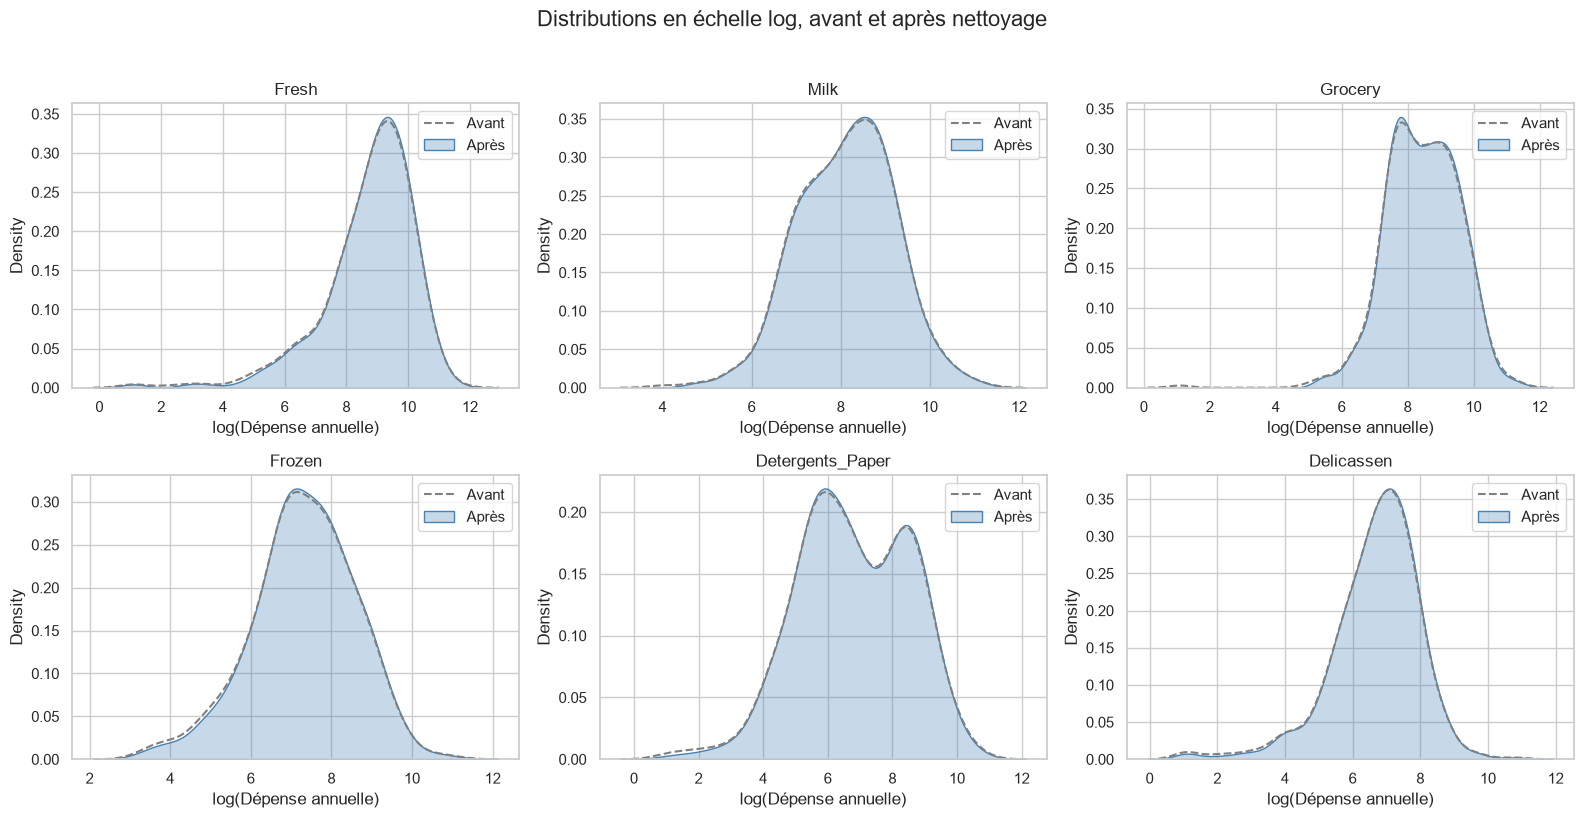

In [45]:
# Distributions en échelle log avant / après nettoyage
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()

for i, col in enumerate(SPEND_COLS):
    sns.kdeplot(np.log(df[col]), ax=axes[i], color="grey", linestyle="--", label="Avant")
    sns.kdeplot(np.log(df_clean[col]), ax=axes[i], color="steelblue", fill=True, alpha=0.3, label="Après")
    axes[i].set_title(col)
    axes[i].set_xlabel("log(Dépense annuelle)")
    axes[i].legend()

plt.suptitle("Distributions en échelle log, avant et après nettoyage", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

In [46]:
# Journal complet du nettoyage
pd.DataFrame(journal)

,Étape,Décision,Lignes avant,Lignes après,Lignes retirées
0,1. Valeurs manquantes,Aucune valeur manquante : aucun traitement,440,440,0
1,2. Doublons,Suppression des doublons exacts (0),440,440,0
2,3. Valeurs aberrantes,Grands comptes conservés (traités par log au FE),440,440,0
3,4. Transactions incohérentes,"Suppression des clients [65, 66, 75, 128, 154]",440,435,5


**Observations :**
- **Tous les contrôles sont validés** : aucune valeur manquante, aucun doublon, aucune dépense nulle ou négative (la transformation log est donc bien définie), codes catégoriels valides et identifiants uniques.
- **Les médianes sont quasiment inchangées** (par exemple `Fresh` : 8 504 → 8 565, `Grocery` : 4 756 → 4 757) : retirer 5 clients sur 440 ne déforme pas les données.
- **L'asymétrie en échelle log diminue**, surtout pour `Grocery` (skewness de -0,74 à **-0,10**), dont la queue gauche venait presque entièrement du client n°75 (3 u.m.). `Delicassen` (-1,18 → -1,05) et `Milk` (-0,23 → -0,14) s'améliorent aussi. `Fresh` reste asymétrique à gauche (-1,59) : de nombreux clients Retail achètent peu de frais, c'est un comportement réel et non une anomalie.
- **La répartition par canal est préservée** : 67,6 % Horeca / 32,4 % Retail après nettoyage, contre 67,7 % / 32,3 % avant.
- Si l'on recalcule la règle IQR en log sur le dataset nettoyé, seuls 2 clients (n°183 et 184) ressortent sur 2 variables. Le n°183 est un grand compte Horeca légitime (maximum de `Delicassen`). On **n'itère pas** la suppression : chaque passage ferait apparaître de nouveaux « extrêmes », et on finirait par éroder des clients réels.

#### 6.7 Préparation des données pour les étapes suivantes
**Pourquoi :** on fige le résultat du nettoyage sous une forme directement réutilisable :
- `X` : la matrice des **6 variables de dépenses**, qui servira à construire la segmentation ;
- `meta` : `Channel` et `Region`, mises de côté pour l'**interprétation** et la **validation** des clusters ;
- un fichier **`data/wholesale_customers_clean.csv`** : le livrable, rechargeable sans réexécuter tout le notebook.

**Ce qui est volontairement laissé au Feature Engineering :** la transformation logarithmique, la **standardisation** et l'ACP. Le scaler doit être ajusté sur les données définitives, puis **réutilisé tel quel** pour affecter un nouveau client (étape 8). Il a donc sa place dans le pipeline de Feature Engineering, et non dans le nettoyage.

In [47]:
# Matrices pour la suite du projet
X = df_clean[FEATURES].copy()      # variables de segmentation (dépenses nettoyées, non transformées)
meta = df_clean[META_COLS].copy()  # canal et région, pour l'interprétation et la validation

# Sauvegarde du livrable
CLEAN_PATH = "data/wholesale_customers_clean.csv"
df_clean.to_csv(CLEAN_PATH, index_label="ID_client")

# Vérification : le fichier rechargé est identique au DataFrame nettoyé
recharge = pd.read_csv(CLEAN_PATH, index_col="ID_client")
assert recharge.equals(df_clean), "Le fichier sauvegardé diffère du DataFrame nettoyé"

print(f"X    : {X.shape[0]} clients x {X.shape[1]} variables -> {list(X.columns)}")
print(f"meta : {meta.shape[0]} clients x {meta.shape[1]} variables -> {list(meta.columns)}")
print(f"Version avec atypiques (analyse de sensibilité) : {df_avec_atypiques.shape[0]} clients")
print(f"\nDataset nettoyé sauvegardé et vérifié : {CLEAN_PATH}")
X.head()

X    : 435 clients x 6 variables -> ['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']
meta : 435 clients x 2 variables -> ['Channel', 'Region']
Version avec atypiques (analyse de sensibilité) : 440 clients

Dataset nettoyé sauvegardé et vérifié : data/wholesale_customers_clean.csv


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
ID_client,,,,,,
0,12669,9656,7561,214,2674,1338
1,7057,9810,9568,1762,3293,1776
2,6353,8808,7684,2405,3516,7844
3,13265,1196,4221,6404,507,1788
4,22615,5410,7198,3915,1777,5185


#### 6.8 Synthèse du nettoyage

| Mission | Constat | Action |
|---|---|---|
| 1. Valeurs manquantes | Aucune (explicite ou déguisée) | Aucune ; imputation par médiane / mode prête si besoin |
| 2. Doublons | Aucun doublon exact ni sur les dépenses | Aucune |
| 3. Valeurs aberrantes | 108 clients aberrants en brut, dont 94 grands comptes cohérents | **Conservés**, influence réduite par le log au Feature Engineering |
| 4. Transactions incohérentes | Aucune valeur impossible ; 5 clients aux profils incohérents (n°65, 66, 75, 128, 154) ; 10 clients avec un montant quasi nul isolé | **5 clients retirés** (1 % du CA) ; 10 clients conservés et suivis |
| 5. Sélection des variables | 6 dépenses pertinentes et variables ; `Channel` / `Region` nominales | `FEATURES` = 6 dépenses ; `META_COLS` = canal, région |
| 6. Qualité | Tous les contrôles validés, distributions et répartition préservées | — |
| 7. Préparation | — | `X`, `meta`, `df_avec_atypiques`, fichier `data/wholesale_customers_clean.csv` |

**Livrable :** un dataset de **435 clients**, propre et cohérent, prêt pour le **Feature Engineering** : transformation logarithmique, standardisation puis ACP.

## 7. Feature Engineering

### 7.1 Transformation logarithmique et standardisation
Les dépenses sont très asymétriques, on applique donc `log` (cohérent avec la section 6), puis on standardise les 6 variables pour qu'elles pèsent de la même façon dans le calcul des distances.

In [ ]:
df = pd.read_csv('data/wholesale_customers_clean.csv')
FEATURES = ['Fresh', 'Milk', 'Grocery', 'Frozen', 'Detergents_Paper', 'Delicassen']

# 7.1 Transformation logarithmique
X_log = np.log1p(df[FEATURES])
print("Asymétrie après log :")
print(X_log.skew().round(2))

Asymétrie après log :
Fresh              -1.53
Milk               -0.14
Grocery            -0.10
Frozen             -0.32
Detergents_Paper   -0.17
Delicassen         -0.97
dtype: float64


In [49]:
from sklearn.preprocessing import StandardScaler

X_log = np.log(X)                      # X vient de la section 6.7 (435 clients)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_log)

print("Moyennes après standardisation :", X_scaled.mean(axis=0).round(2))
print("Écarts-types après standardisation :", X_scaled.std(axis=0).round(2))

Moyennes après standardisation : [-0. -0.  0. -0.  0. -0.]
Écarts-types après standardisation : [1. 1. 1. 1. 1. 1.]
